# Standard and physics-informed MLP validation

This notebook reads the **saved training-only experiments**. It does not train models.
All comparisons use the same 800 development plants and three grouped folds; the 200 test plants remain excluded.
The selected seed-42 results are development scores used for model selection, not unbiased final-test scores.

Select the project `.venv-review` Python kernel and run top to bottom.

In [1]:
from pathlib import Path
import sys, os
for variable in ["OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[variable] = "1"
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "report_mlp.py").exists())
sys.path.insert(0, str(root / "scripts"))
sys.path.insert(0, str(root / "src"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from report_mlp import comparison_results, epoch_plot, seed_plot, data_size_plot
from plot_baselines import style, prediction_plot, objective_plot, overshoot_plot, overshoot_bins_plot, example_rows, response_plot, revalidate
style()
metrics, predictions, selected = comparison_results()
seeds = pd.read_csv(root / "results" / "mlp_experiments" / "seed_results.csv")
import json
protocol = json.loads((root / "results" / "mlp_experiments" / "protocol.json").read_text())
display(metrics.round(3))
display(selected[["variant", "beta", "dropout", "weight_decay", "median_best_epoch", "success_pct"]])

,success_pct,stable_pct,r2,median_J_ratio,passes
model,,,,,
random_forest,66.250,97.625,0.822,1.203,530
xgboost,69.625,99.250,0.628,1.218,557
standard_mlp,81.625,100.000,0.945,1.142,653
physics_mlp,81.875,100.000,0.945,1.143,655


,variant,beta,dropout,weight_decay,median_best_epoch,success_pct
0,standard,0.0,0.05,0.0001,484,81.625
1,physics,1.0,0.05,0.0001,484,81.875


## What the network learns

Inputs are the same five empirical response features. Training targets are normalized using estimated final output and rise time:
`q = [y_ss*Kp, y_ss*t_rise*Ki, y_ss*Kd/t_rise]`.
The network predicts positive q, then reverses this scaling using only those measured features.

The standard loss is per-target standardized squared log error in q. The physics variant adds scaled Hurwitz violations from the matching second-order Padé model, with a separate exact-zero-delay cubic. Physical parameters enter the **physics loss during training/validation only**, not inference. This extra training information must be considered when comparing to the standard MLP or trees. It does not guarantee stability or overshoot compliance.

Early stopping uses validation total loss. The model settings are selected using controller pass count, then regularized J among accepted pairs. No extra gain cost or differentiable trajectory rollout is added during neural training.

## Training and validation loss

Solid lines are training loss; dashed lines are validation loss. Each color is a fold. Losses include different physics weights across the variants, so compare train versus validation **within each variant**, rather than interpreting absolute heights across variants.

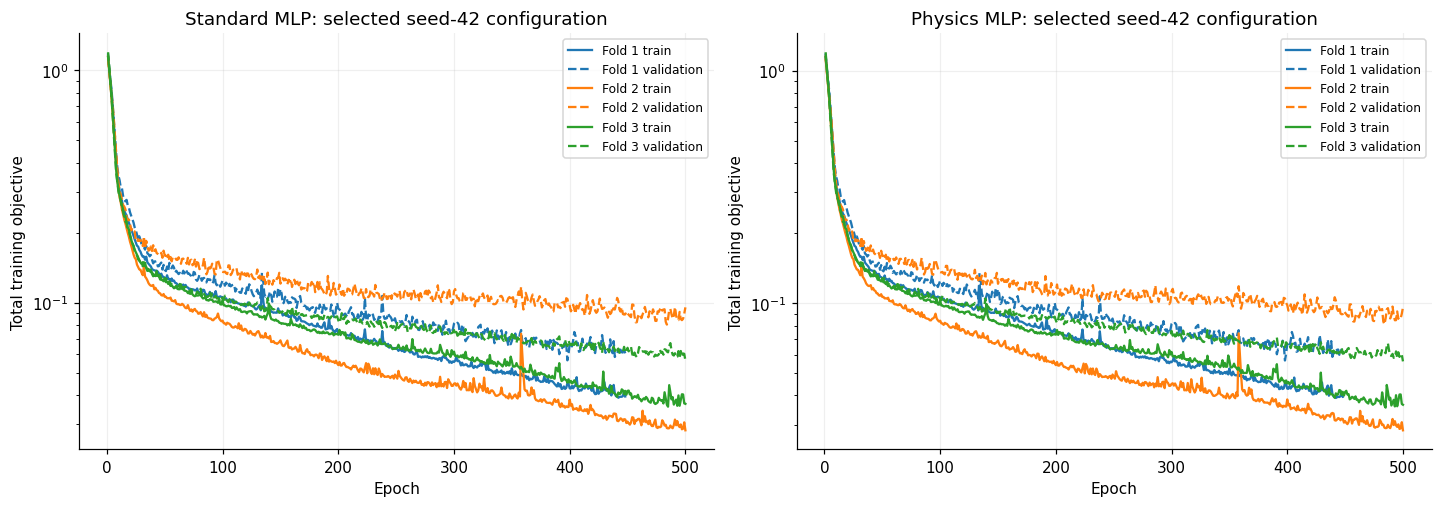

In [2]:
fig = epoch_plot(selected)
plt.show()

## Sample-size learning curves

Both selected MLPs also train on nested 128- and 256-plant subsets inside the same development folds. The full folds contain 533 or 534 training plants. Subset permutations match the earlier tree experiments. Scaling is fitted only on each subset, and early stopping remains enabled. Settings were selected at full size, so these are descriptive development curves, not unbiased final-test estimates.

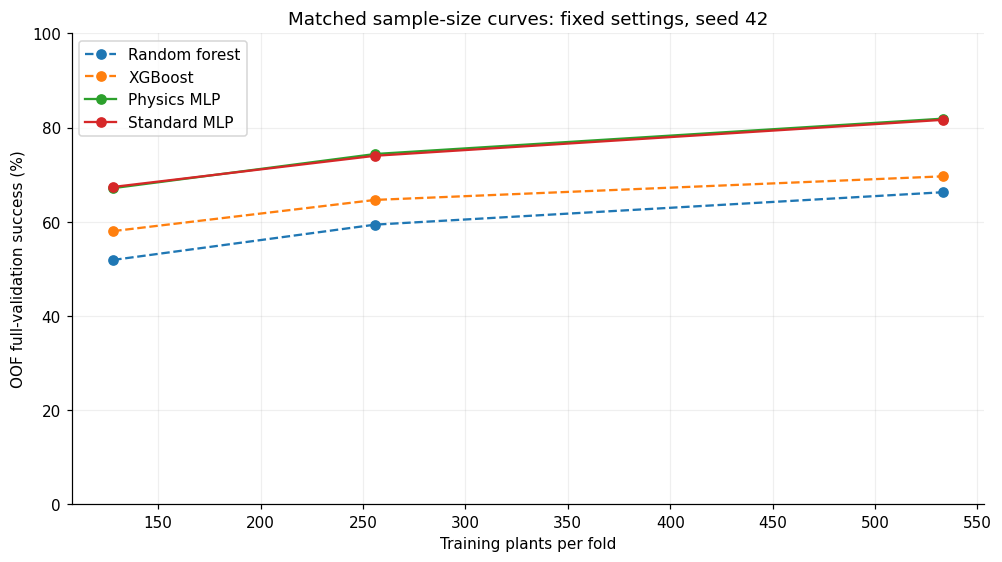

,variant,training_size,success_pct,stable_pct,r2
4,physics,128,67.125,99.75,0.861030
5,physics,256,74.375,100.00,0.875735
3,physics,533,81.875,100.00,0.945228
1,standard,128,67.375,99.75,0.860021
2,standard,256,74.000,100.00,0.875368
0,standard,533,81.625,100.00,0.945157


In [3]:
fig = data_size_plot()
plt.show()
display(pd.read_csv(root / "results" / "mlp_experiments" / "learning_curves.csv")[["variant", "training_size", "success_pct", "stable_pct", "r2"]].sort_values(["variant", "training_size"]))

## Initialization sensitivity

Each dot is a different seed on the same data folds; black bars are means. Settings were selected using seed 42, then repeated at seeds 43 and 44 without retuning. This measures initialization sensitivity, not uncertainty across new datasets. Tree comparison lines are their existing single-seed development results.

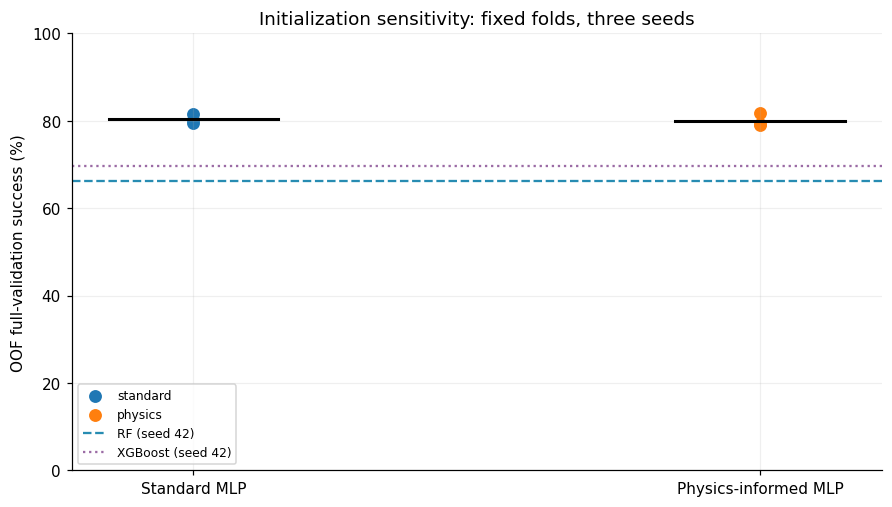

,variant,seed,success_pct,stable_pct,r2,median_J_ratio
0,standard,42,81.625,100.0,0.945,1.142
1,standard,43,79.500,100.0,0.909,1.150
2,standard,44,80.250,100.0,0.929,1.154
3,physics,42,81.875,100.0,0.945,1.143
4,physics,43,79.250,100.0,0.909,1.149
5,physics,44,79.000,100.0,0.930,1.155


In [4]:
fig = seed_plot(seeds, metrics)
plt.show()
display(seeds[["variant", "seed", "success_pct", "stable_pct", "r2", "median_J_ratio"]].round(3))

## Gain predictions

Blue predictions passed full validation; orange predictions failed. The diagonal represents the optimized target. All plotted gains are **decoded physical PID gains**, not normalized targets.

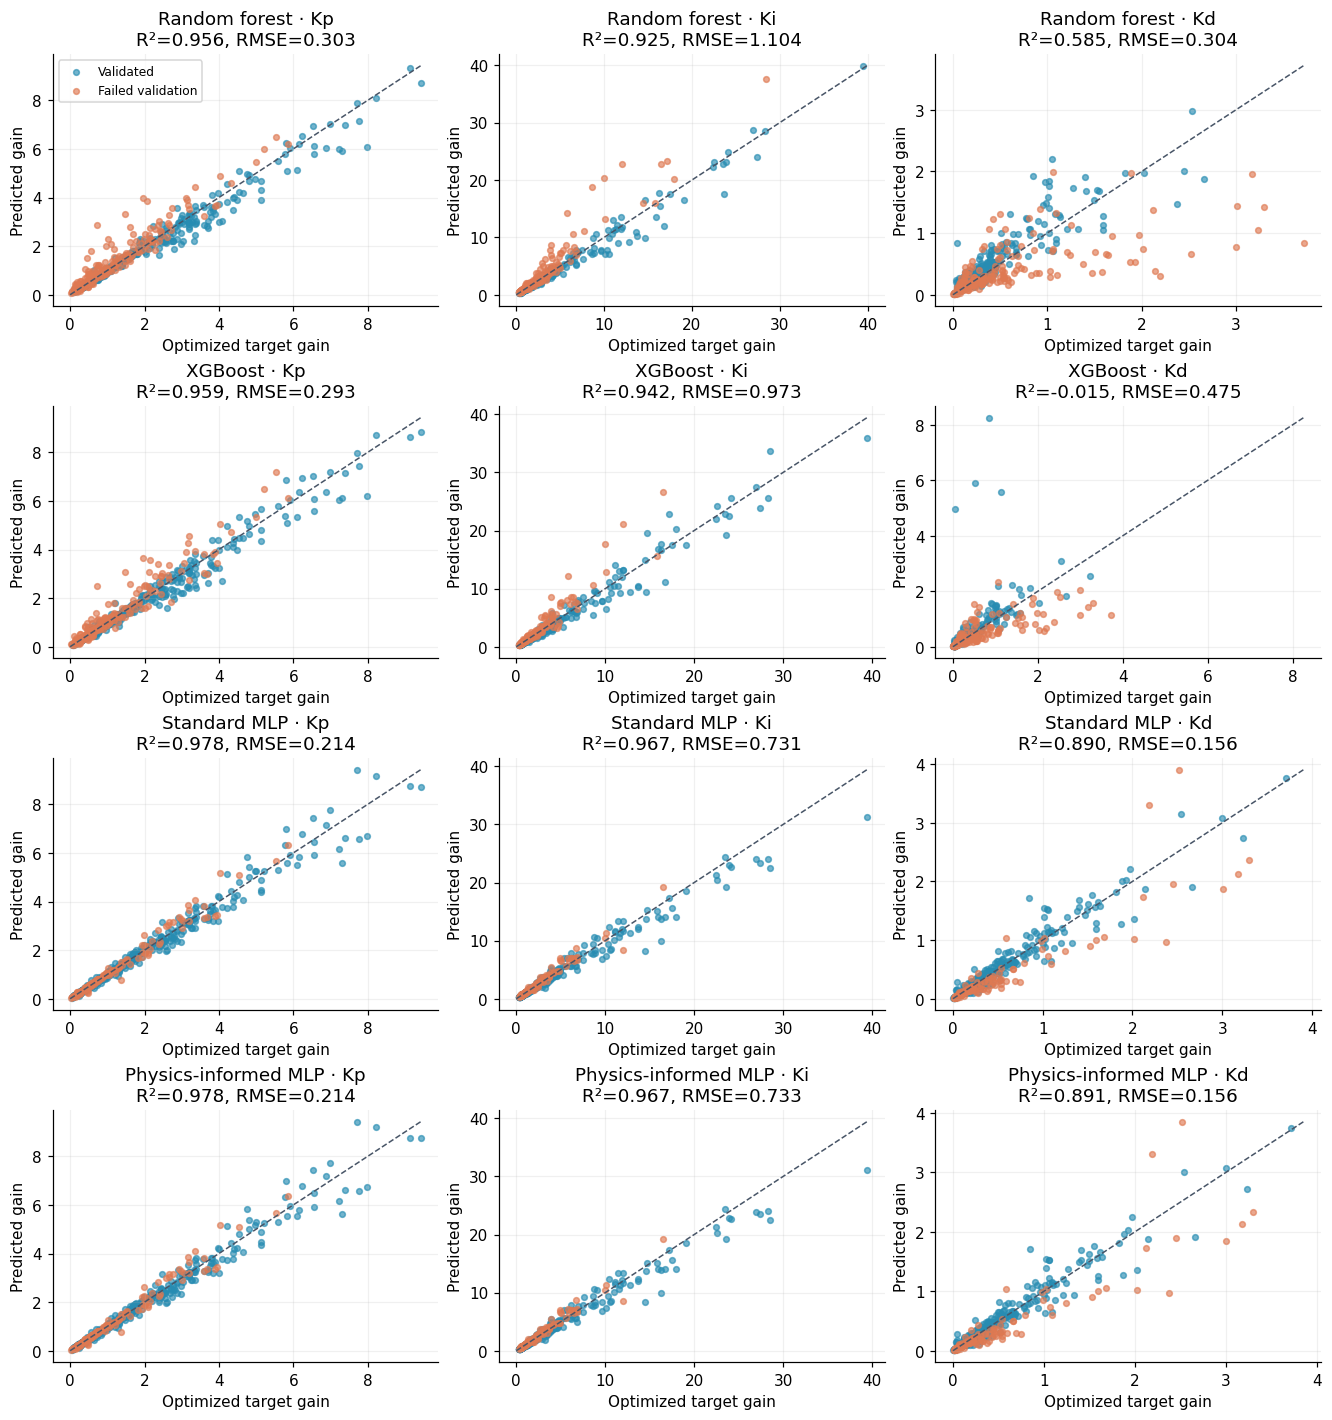

In [5]:
fig = prediction_plot(predictions)
plt.show()

## Overshoot severity

Stable measured predictions are shown. Unstable and unmeasured cases are counted separately. Measurements for rejected controllers are finite-window diagnostics; merely being below 10% is not full validation.

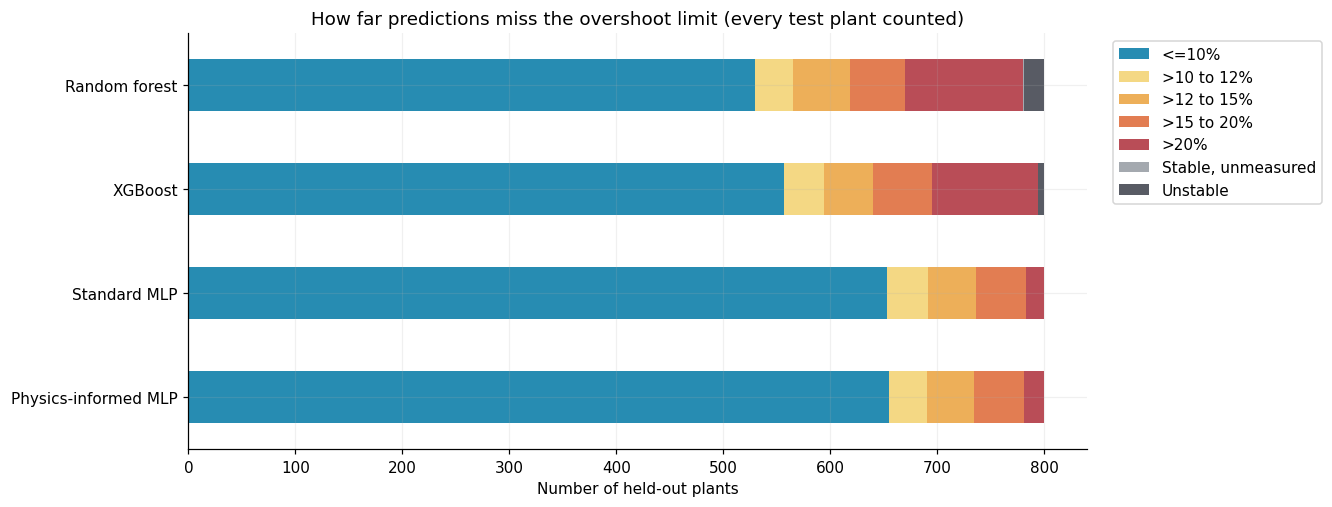

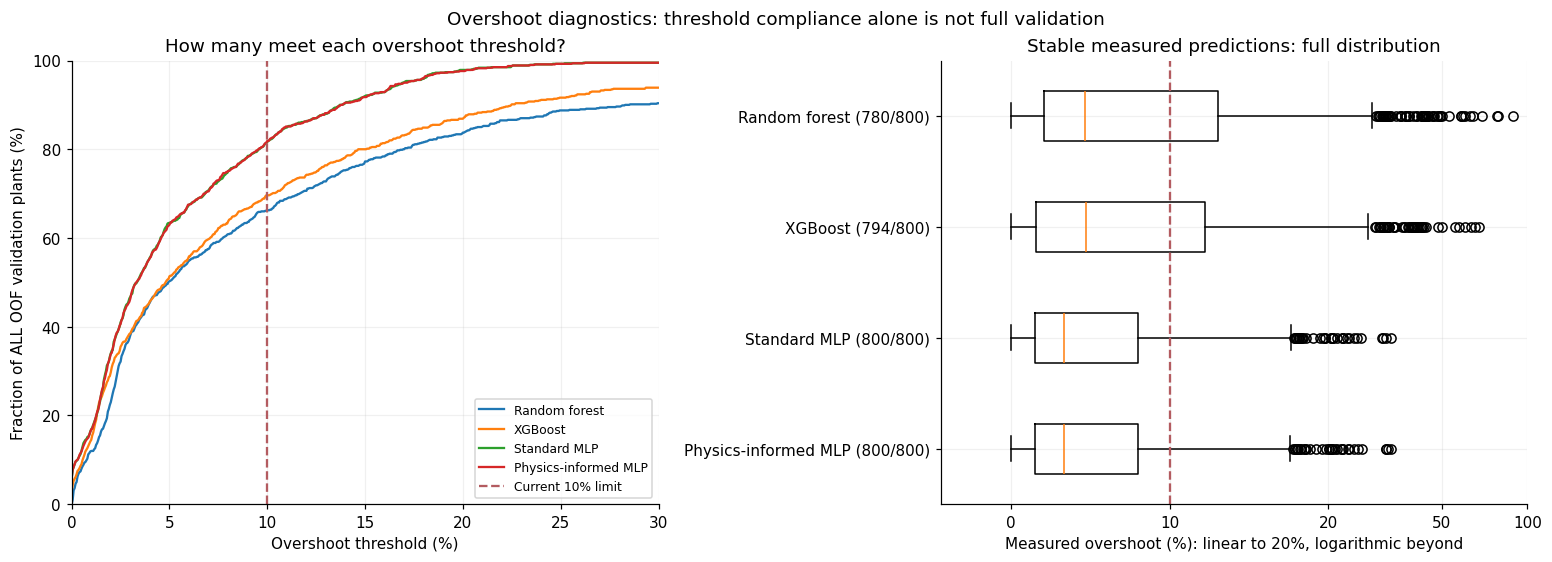

In [6]:
fig = overshoot_bins_plot(predictions)
plt.show()
fig = overshoot_plot(predictions, population_label="OOF validation plants")
plt.show()

## Regularized controller cost

J is the same normalized ITAE plus gain penalty used for label generation, with lambda=0.01. A ratio of 1 matches the reference cost. Only pairs where both controllers passed are included; counts expose coverage. Failed controllers remain in the full-pass denominator. Different accepted subsets prevent ranking models by these medians alone.

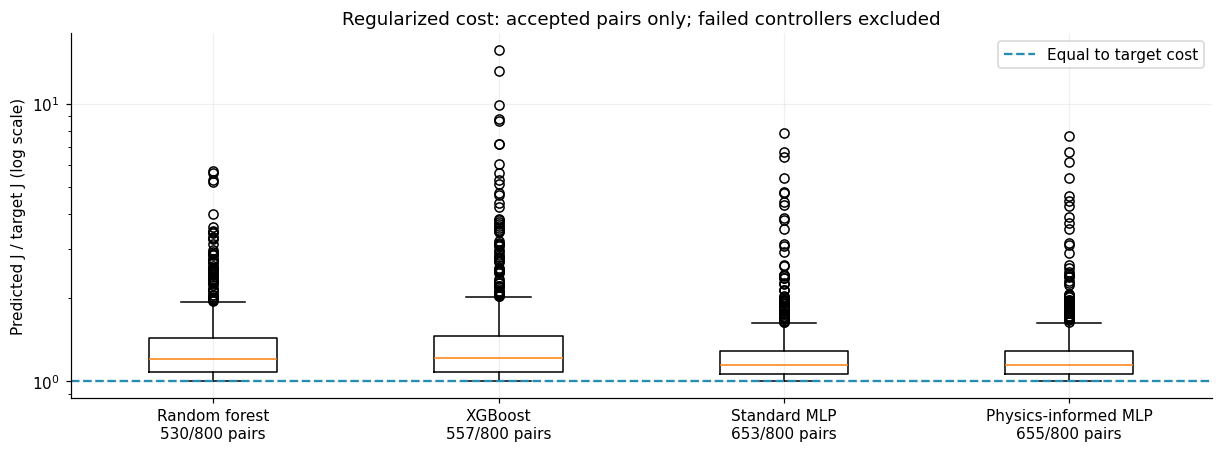

In [7]:
fig = objective_plot(predictions)
plt.show()

## Shared-plant response examples

Examples are chosen from the random forest out-of-fold predictions: median accepted cost, median measured overshoot failure, and the first zero-delay case. These are illustrations, not a representative performance sample. Display windows may be shorter than validation horizons, and divergent curves may exceed the output-axis limits.

In [8]:
examples = example_rows(predictions)
display(pd.Series(examples, name="Original CSV row ID"))

Representative RF success               37
Representative RF overshoot failure    977
Zero-delay example                      26
Name: Original CSV row ID, dtype: int64

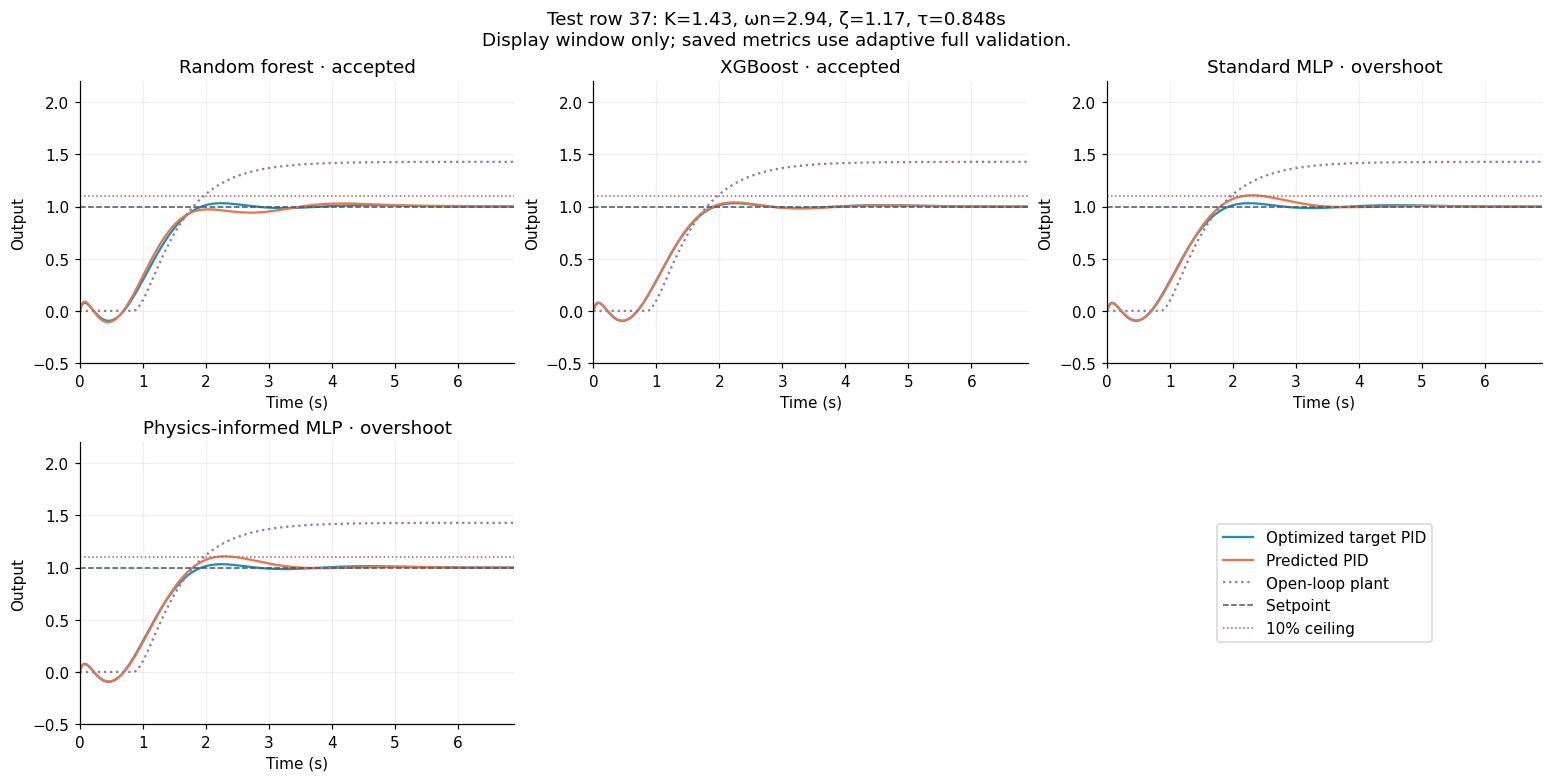

In [9]:
fig = response_plot(predictions, examples["Representative RF success"])
plt.show()

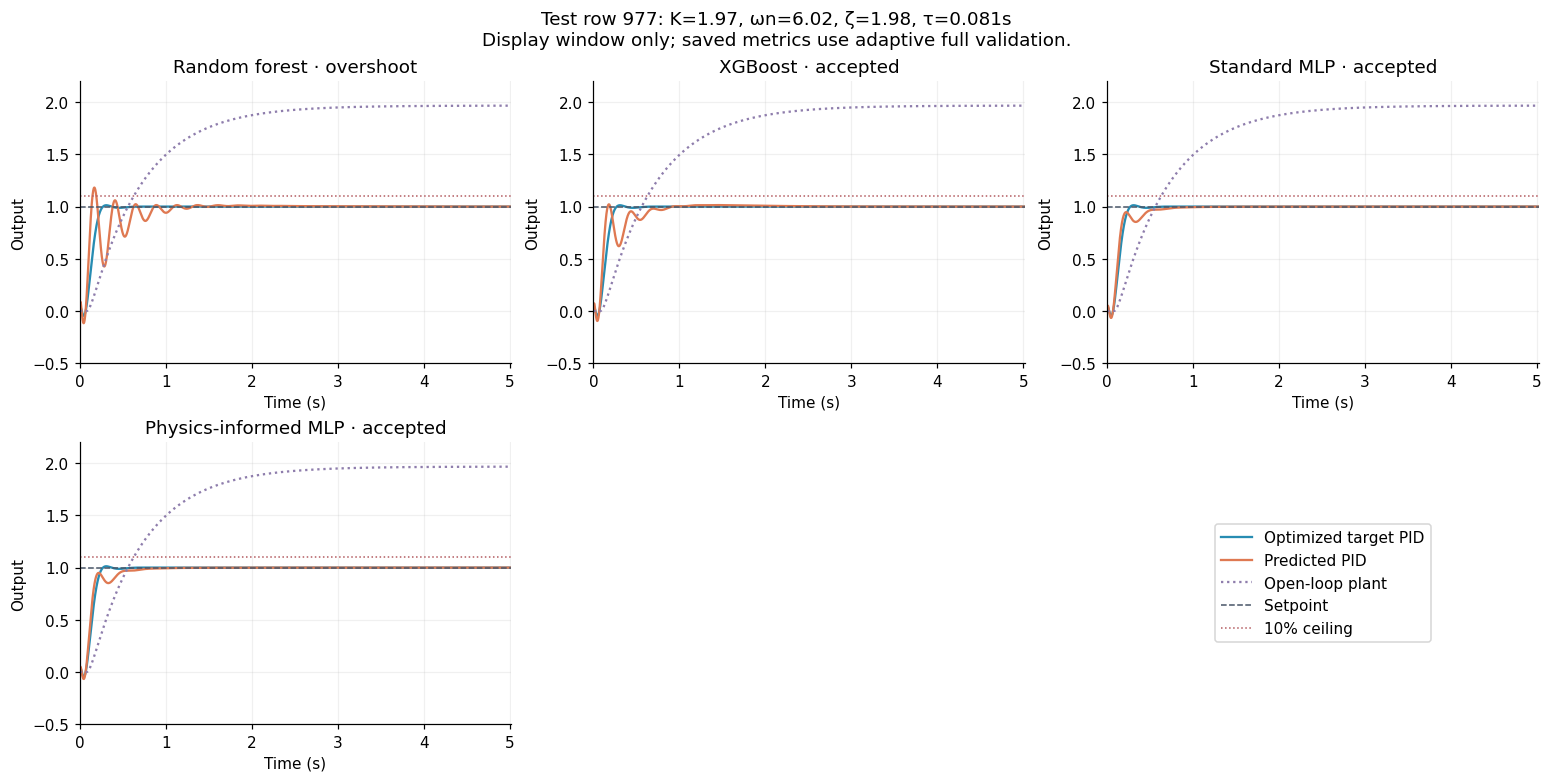

In [10]:
fig = response_plot(predictions, examples["Representative RF overshoot failure"])
plt.show()

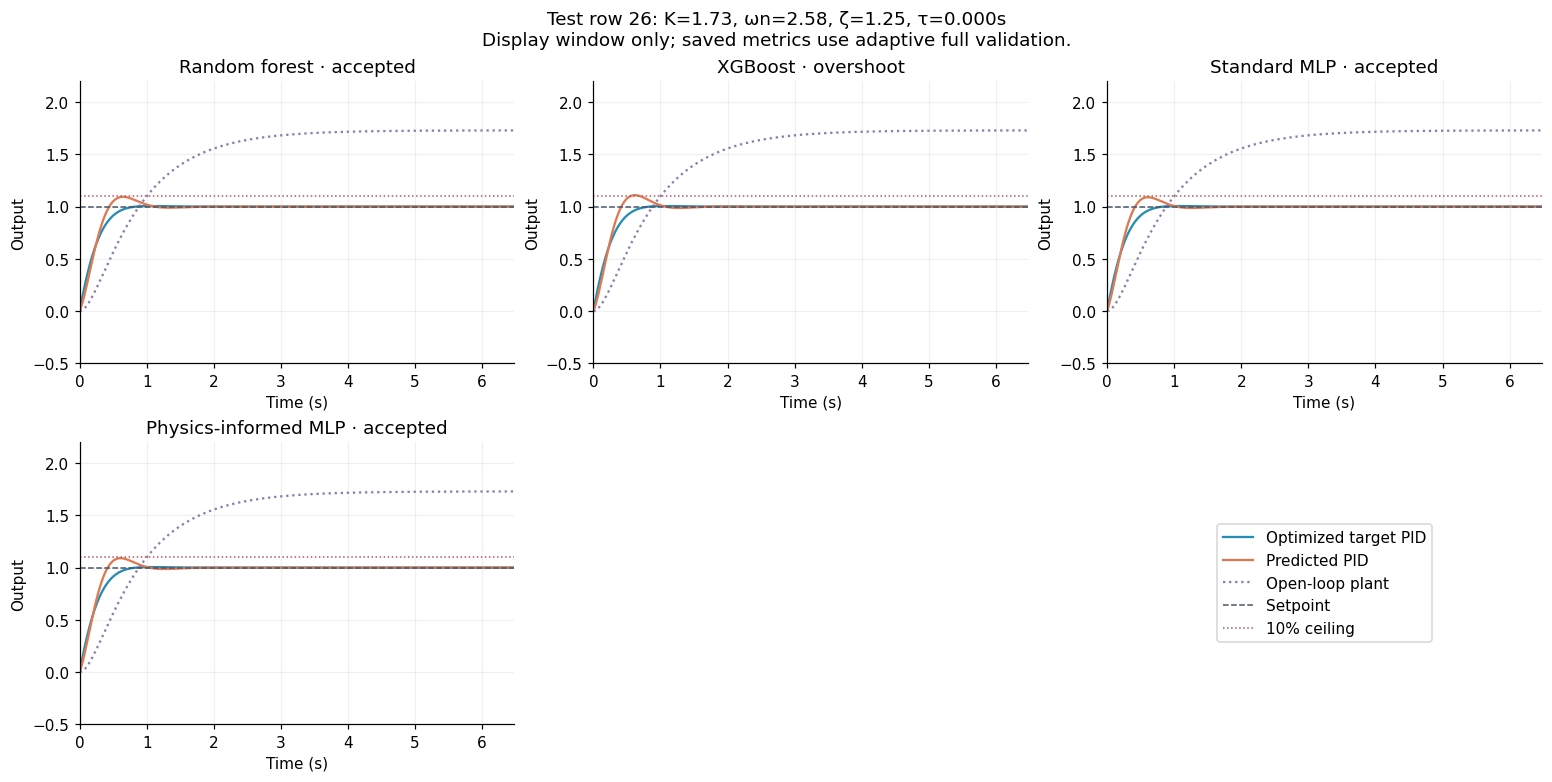

In [11]:
fig = response_plot(predictions, examples["Zero-delay example"])
plt.show()

## Revalidate the illustrated predictions

This reruns the shared pole, gain-bound, refined-overshoot, tail-error, and numerical-convergence checks on these saved predictions. It does not train or use any held-out test plants.

In [12]:
checks = revalidate(predictions, protocol, source_rows=list(examples.values()))
display(checks)
print("Matching saved outcomes:", checks.matches.sum(), "/", len(checks))

,model,source_row,saved_reason,fresh_reason,matches,overshoot_pct,objective
0,random_forest,26,accepted,accepted,True,9.355165e+00,0.704787
1,random_forest,37,accepted,accepted,True,2.978570e+00,9.939494
2,random_forest,977,overshoot,overshoot,True,1.820292e+01,NaN
3,xgboost,26,overshoot,overshoot,True,1.090760e+01,NaN
4,xgboost,37,accepted,accepted,True,3.961520e+00,8.286305
5,xgboost,977,accepted,accepted,True,2.175246e+00,2.520696
6,standard_mlp,26,accepted,accepted,True,8.961799e+00,0.739402
7,standard_mlp,37,overshoot,overshoot,True,1.080526e+01,NaN
8,standard_mlp,977,accepted,accepted,True,2.442491e-13,1.263446
9,physics_mlp,26,accepted,accepted,True,9.030761e+00,0.741842


Matching saved outcomes: 12 / 12


## Load the final refitted model

Final `.pt` files include architecture, weights and fitted scaling. The models were refitted on all 800 development plants for the selected median stopping epoch; their predictions need not equal out-of-fold predictions made by smaller fold-specific models.

```python
from MLP import MLPModel
model = MLPModel.load(root / "results/mlp_experiments/standard_mlp.pt")
gains = model.predict(feature_frame[["t_rise", "t_settling", "y_peak", "y_ss", "tau_est"]])
```

No physical parameters are needed for inference. Full numerical details are in `results/mlp_experiments/report.md`.
To rerun training, use `python scripts/train_mlp.py`, then `python scripts/report_mlp.py`; training is intentionally not run by this notebook.

# New experiment: 20,000 plants

The earlier notebook sections above are preserved and describe the old 1,000-row experiment.
**Everything below uses `data/pid_dataset_20000.csv` and the frozen 15,000 training / 2,500 validation / 2,500 test split.**

The final test set was scored after settings and weights were frozen. These are new test results, not the earlier development-fold scores. No post-test tuning is performed.
All models use the same five empirical features and normalized targets. The standard MLP uses log-space supervised loss; the physics loss is disabled.

Restart the kernel and Run All to refresh imports and saved results. No model training is run by this notebook.

In [13]:
from pathlib import Path
import sys
large_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "report_20000.py").exists())
sys.path.insert(0, str(large_root / "scripts"))
sys.path.insert(0, str(large_root / "src"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from large_experiment import load_models_results, OUT as LARGE_RESULTS
from report_20000 import learning_plot, mlp_history_plot
from plot_baselines import (performance_plot, prediction_plot, failure_plot, objective_plot,
                           itae_plot, overshoot_plot, overshoot_bins_plot, overshoot_summary,
                           example_rows, response_plot, revalidate)
large_mlp_names = ['random_forest', 'xgboost', 'standard_mlp']
large_mlp_metrics, large_mlp_predictions, large_mlp_protocol = load_models_results(large_mlp_names)
print("Training:", len(large_mlp_protocol["train"]), "Validation:", len(large_mlp_protocol["validation"]), "Test:", len(large_mlp_protocol["test"]))
print("Dataset SHA-256:", large_mlp_protocol["dataset_sha256"])
display(large_mlp_metrics[["success_pct", "stable_pct", "bounds_violation_pct", "r2", "median_J_ratio", "ratio_pairs"]].round(3))

Training: 15000 Validation: 2500 Test: 2500
Dataset SHA-256: 0bd540d44914e6dfcb76179688639203004f0a6ec3ac161ea7ca4c399dae2ba0


,success_pct,stable_pct,bounds_violation_pct,r2,median_J_ratio,ratio_pairs
model,,,,,,
random_forest,91.88,100.0,0.0,0.961,1.044,2297
xgboost,87.92,100.0,0.0,0.961,1.109,2198
standard_mlp,97.92,100.0,0.0,0.987,1.042,2448


## New test performance and gain predictions

Gain errors compare decoded physical PID gains with optimized targets. Full validation additionally checks bounds, stable poles, refined overshoot <=10%, tail error <=0.001, and ITAE convergence. No prediction clipping or fallback is applied.

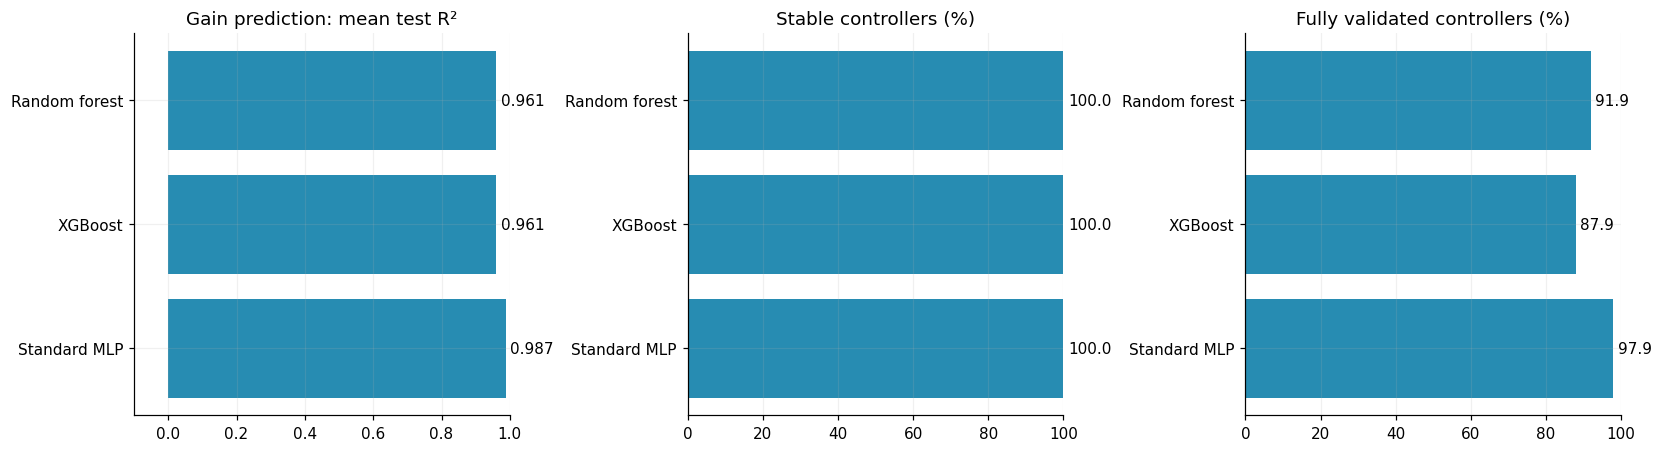

In [14]:
fig = performance_plot(large_mlp_metrics)
plt.show()

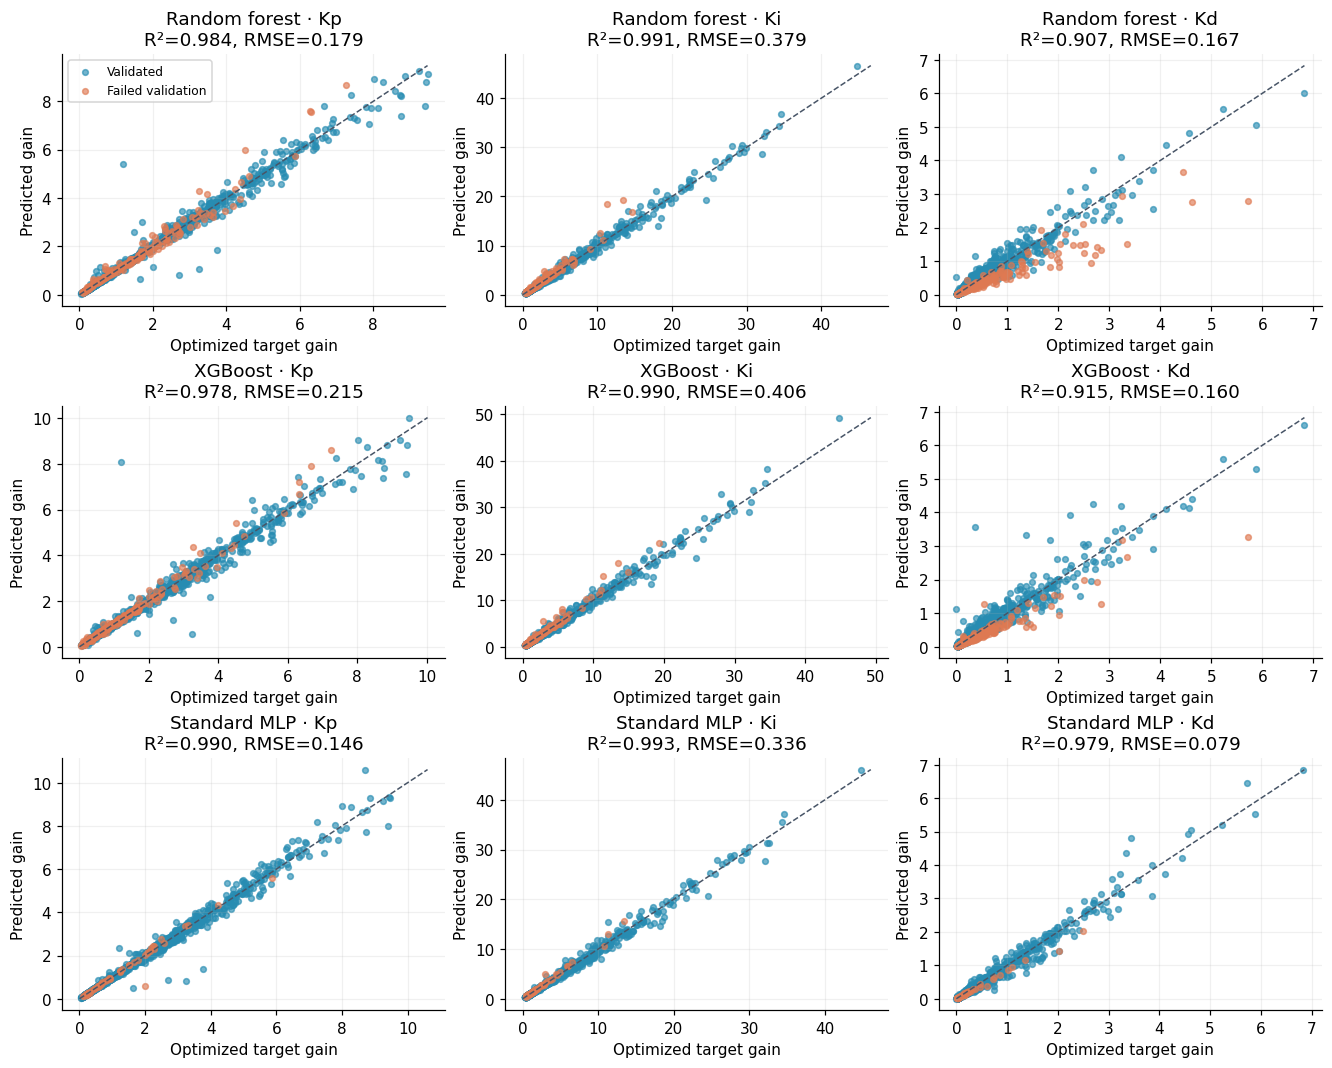

In [15]:
fig = prediction_plot(large_mlp_predictions)
plt.show()

## ITAE: how much did tracking change from the optimized controller?

The scatter compares raw ITAE on matching plants; the diagonal means equality.
The ratio is `ITAE_predicted / ITAE_target`; 1 means equal. Percentage change is `100*(ratio-1)`; 0% means equal and +20% means 20% larger time-weighted error.

**Only validated prediction/reference pairs are plotted**, with counts shown. Failed/unstable/unresolved controllers remain failures and are never assigned zero error. Raw ITAE and regularized J are different: lower ITAE alone may require larger gains and need not improve J. Target gains come from local optimization, so a prediction can occasionally improve upon them.

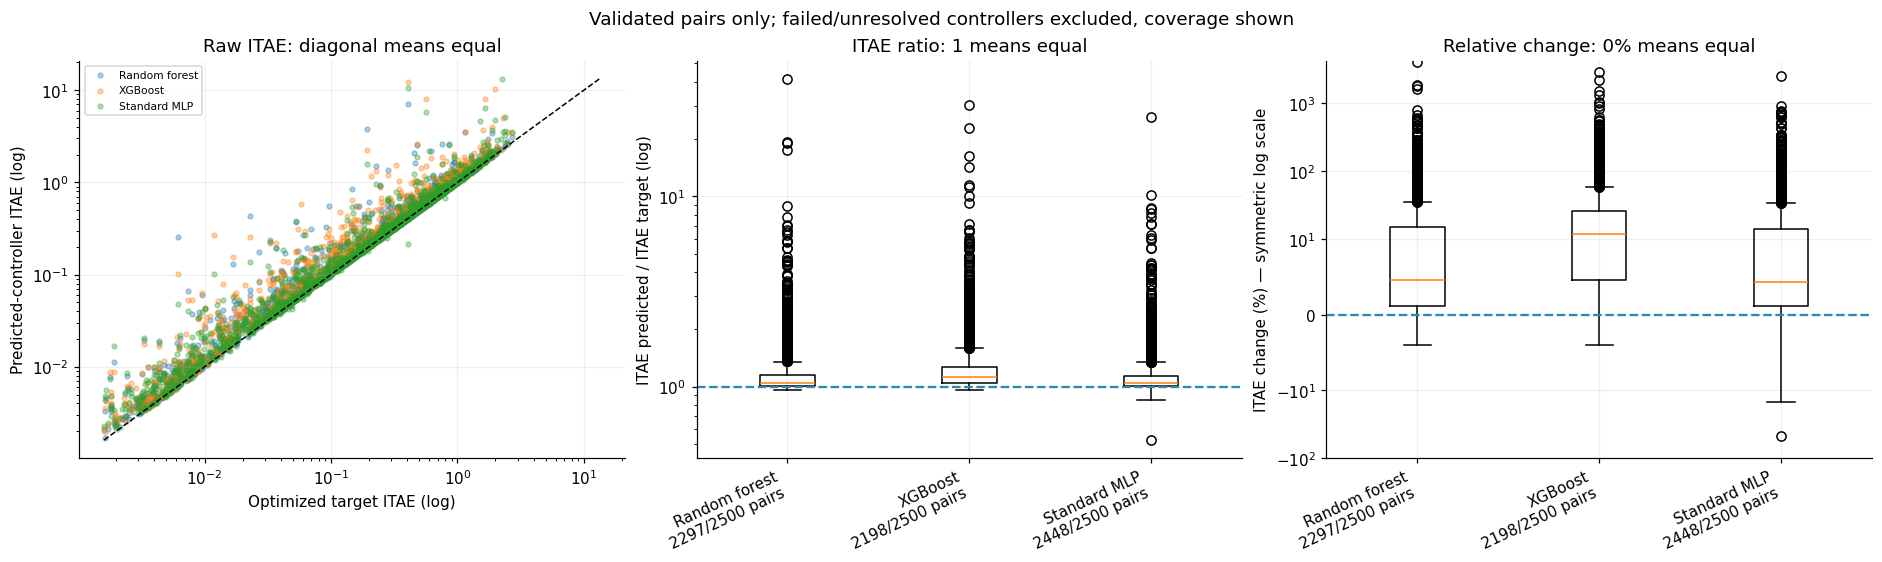

,model,paired_count,median_ITAE_ratio,p90_ITAE_ratio,median_ITAE_change_pct
3,random_forest,2297,1.046,1.481,4.628
4,xgboost,2198,1.118,1.716,11.827
5,standard_mlp,2448,1.043,1.495,4.282


In [16]:
fig = itae_plot(large_mlp_predictions)
plt.show()
display(pd.read_csv(LARGE_RESULTS / "itae_summary.csv").query("model in @large_mlp_names").round(3))

## Regularized objective J

J includes normalized ITAE plus the squared dimensionless-gain penalty at lambda=0.01. Ratios use accepted pairs only and their coverage differs by model. Do not rank models by these conditional medians alone.

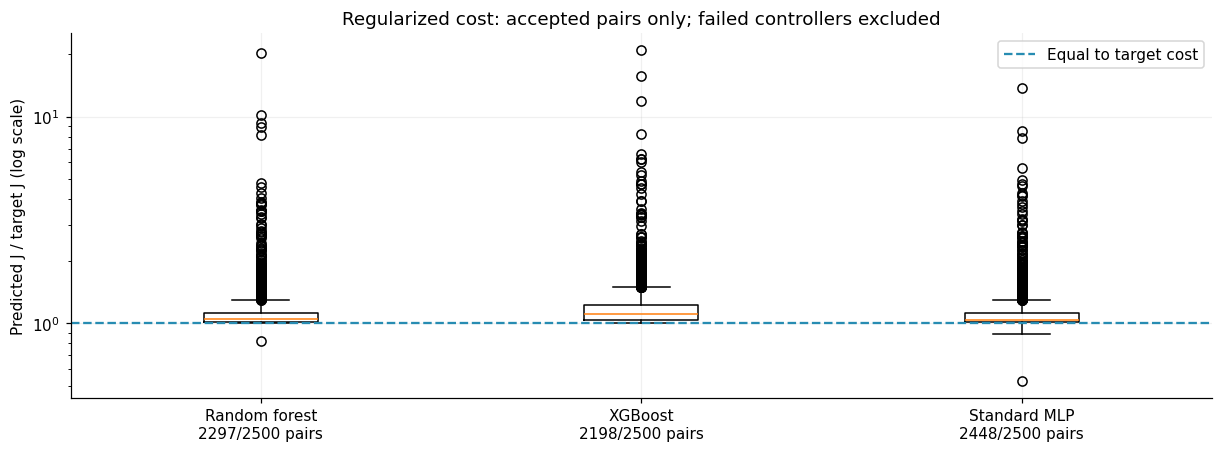

In [17]:
fig = objective_plot(large_mlp_predictions)
plt.show()

## Failures and overshoot severity

Below-limit overshoot alone is not full validation. Stable finite-window measurements for rejected controllers are diagnostic; missing/unstable cases are counted separately.

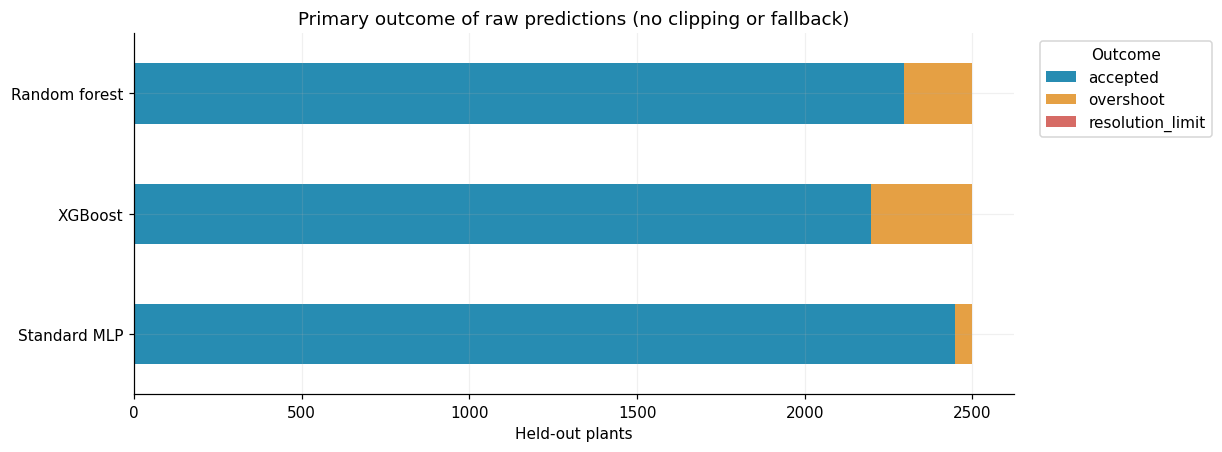

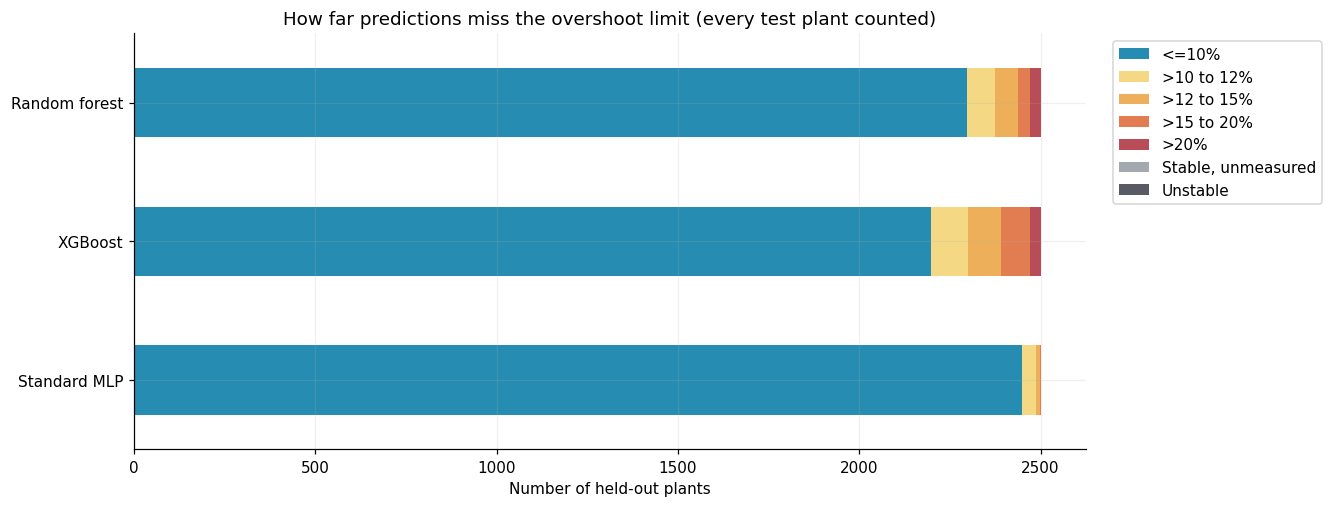

In [18]:
fig = failure_plot(large_mlp_predictions)
plt.show()
fig = overshoot_bins_plot(large_mlp_predictions)
plt.show()

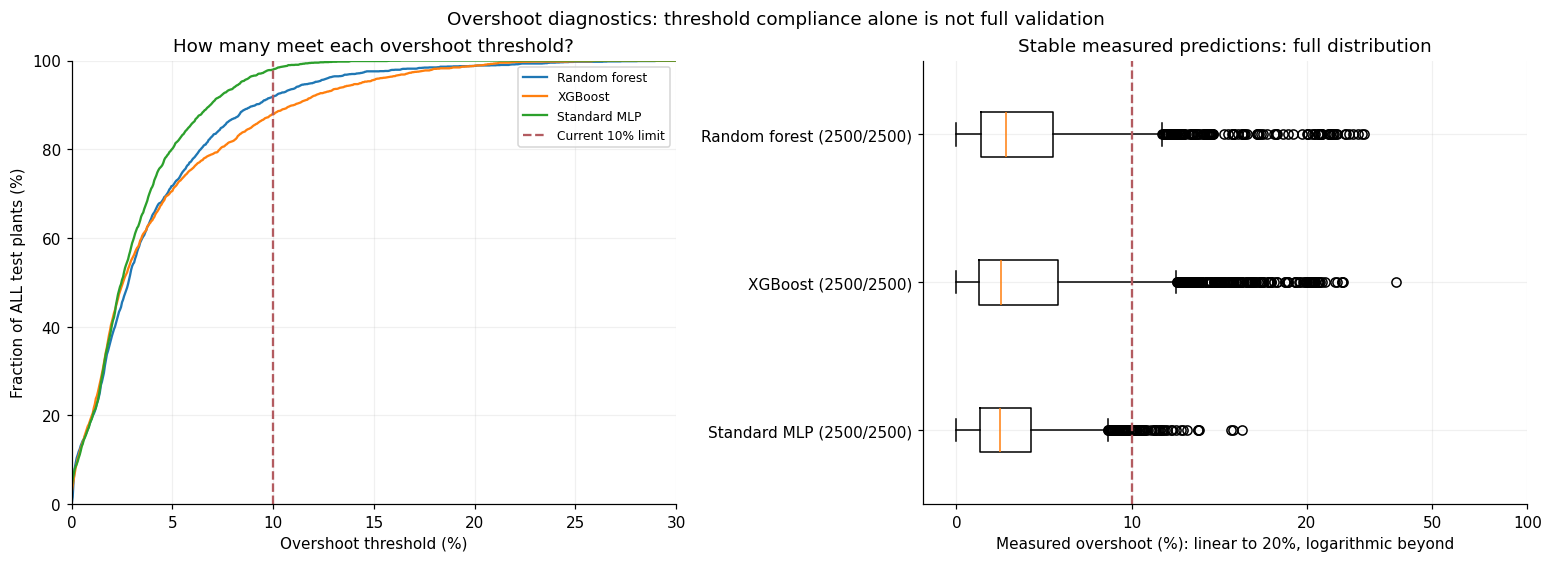

,test_plants,measured_stable,at_most_10,over_10_to_12,over_12_to_15,over_15_to_20,over_20,stable_unmeasured,unstable,median_overshoot_pct,p90_overshoot_pct,max_overshoot_pct,median_excess_pp,p90_excess_pp,full_validation_passes
model,,,,,,,,,,,,,,,
random_forest,2500,2500,2297,78,64,31,30,0,0,2.816,9.129,30.245,2.680,12.146,2297
xgboost,2500,2500,2198,102,91,79,30,0,0,2.549,11.049,38.241,3.456,9.956,2198
standard_mlp,2500,2500,2449,38,10,3,0,0,0,2.467,6.889,16.319,0.898,3.788,2448


In [19]:
fig = overshoot_plot(large_mlp_predictions)
plt.show()
display(overshoot_summary(large_mlp_predictions).round(3))

## Learning curves from the larger training set

Each model uses the same nested random training subsets (1,000 / 5,000 / 10,000 / 15,000) and fixed selected settings.
The curves use the **same 500 stratified validation plants**, not the test set. The MLP uses the full 2,500 validation set for early stopping at every size. These are development diagnostics; settings and stopping used validation data.

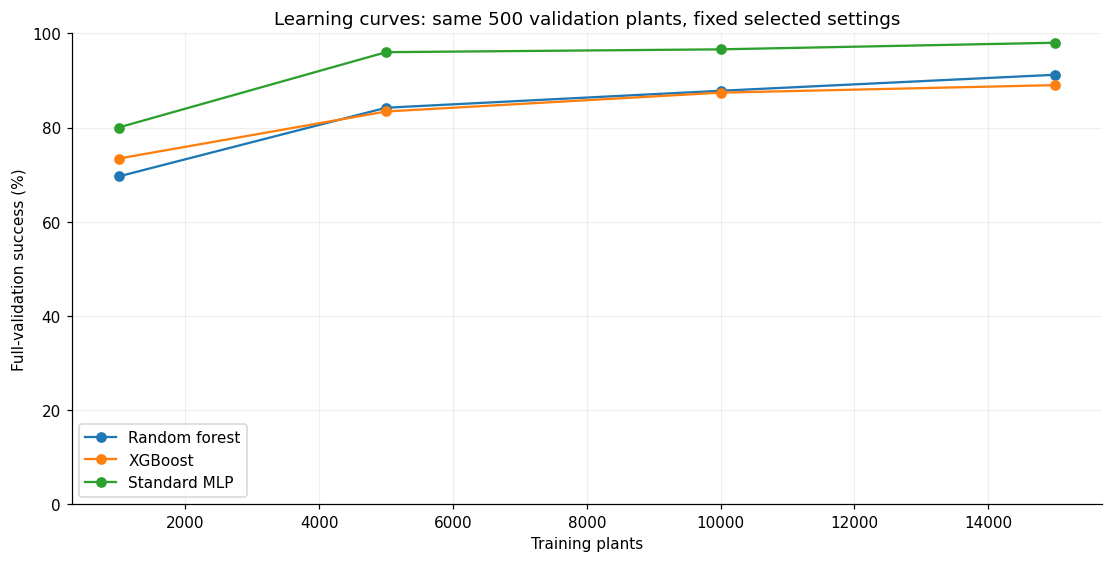

,model,training_size,success_pct,r2,median_J_ratio
15,random_forest,1000,69.6,0.905,1.138
16,random_forest,5000,84.2,0.946,1.061
17,random_forest,10000,87.8,0.961,1.049
3,random_forest,15000,91.2,0.969,1.043
21,standard_mlp,1000,80.0,0.959,1.110
22,standard_mlp,5000,96.0,0.977,1.073
23,standard_mlp,10000,96.6,0.981,1.056
5,standard_mlp,15000,98.0,0.984,1.050
18,xgboost,1000,73.4,0.837,1.174
19,xgboost,5000,83.4,0.955,1.153


In [20]:
fig = learning_plot(large_mlp_names)
plt.show()
display(pd.read_csv(LARGE_RESULTS / "learning_curves.csv").query("model in @large_mlp_names")[["model", "training_size", "success_pct", "r2", "median_J_ratio"]].sort_values(["model", "training_size"]).round(3))

### Standard MLP training history

The architecture remains 5-128-64-32-3. Batch size is 256 for efficient training on 15,000 plants. Early stopping restores the best validation-loss checkpoint. Input and target scales come only from training data.

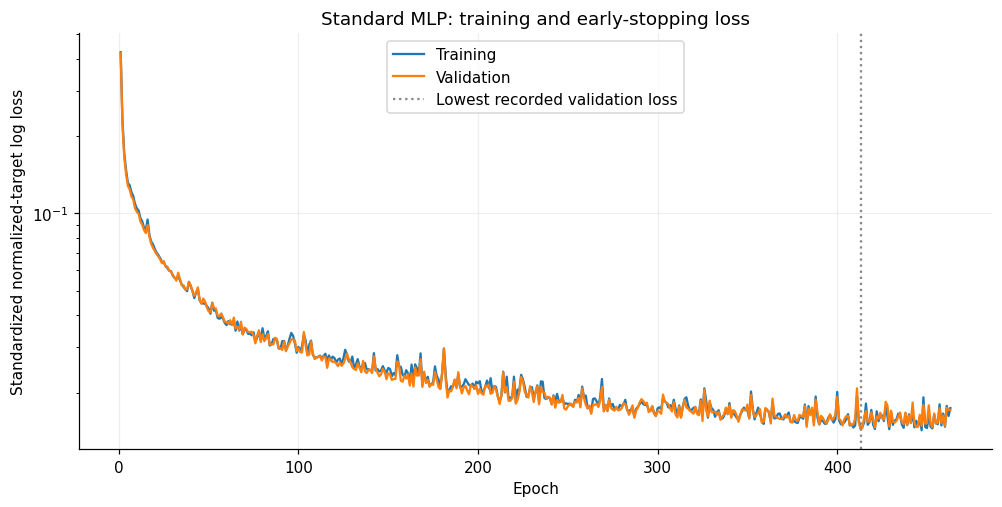

In [21]:
fig = mlp_history_plot()
plt.show()

## Shared test-plant response examples

Examples are selected transparently from random forest results: median accepted cost ratio and median stable overshoot failure. They are illustrations, not a balanced test sample. Display windows can be shorter than full validation horizons.

In [22]:
large_mlp_examples = example_rows(large_mlp_predictions)
display(pd.Series(large_mlp_examples, name="20k CSV row ID"))

Representative RF success               7688
Representative RF overshoot failure    17183
Zero-delay example                        65
Name: 20k CSV row ID, dtype: int64

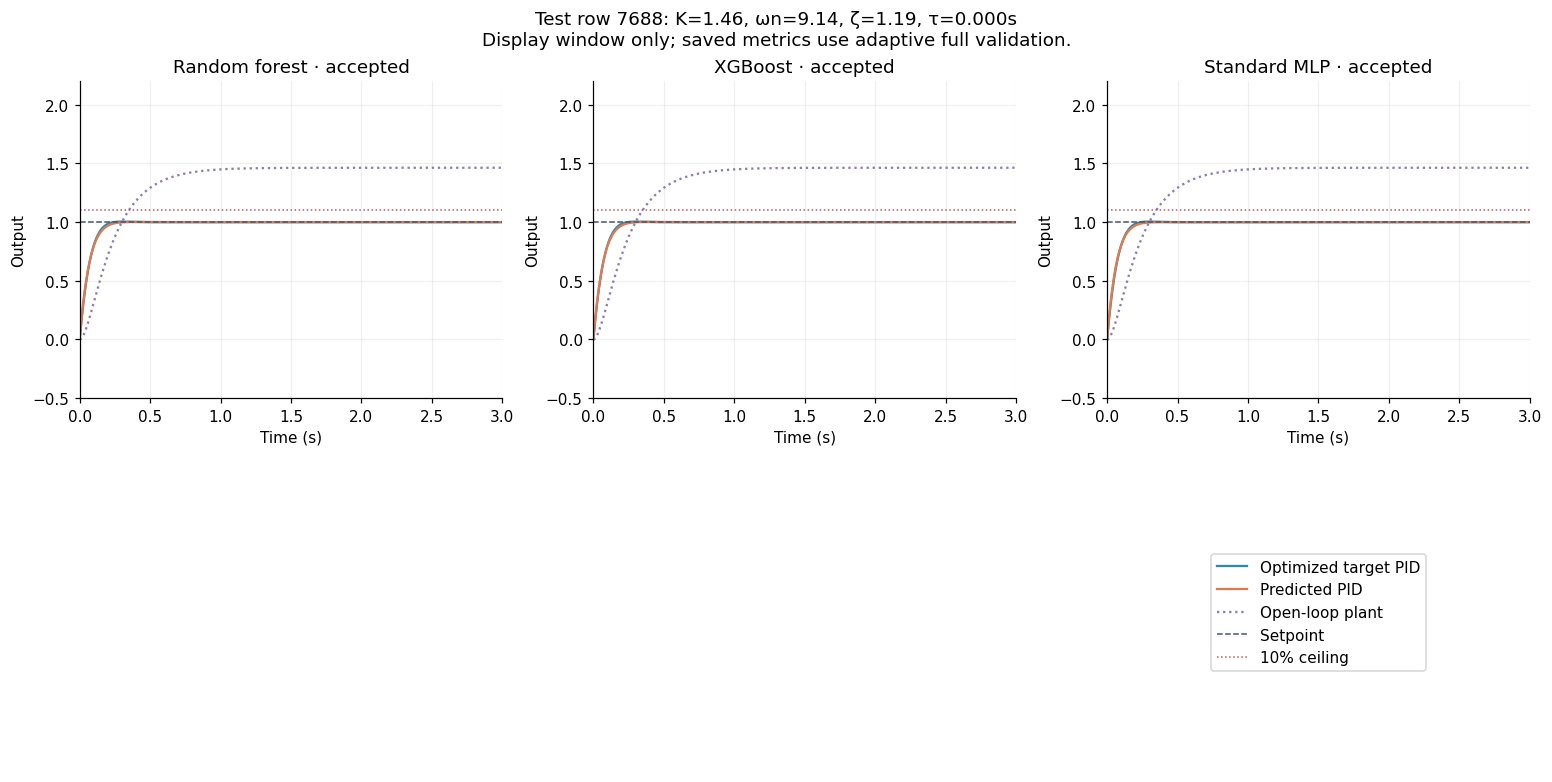

In [23]:
fig = response_plot(large_mlp_predictions, large_mlp_examples["Representative RF success"])
plt.show()

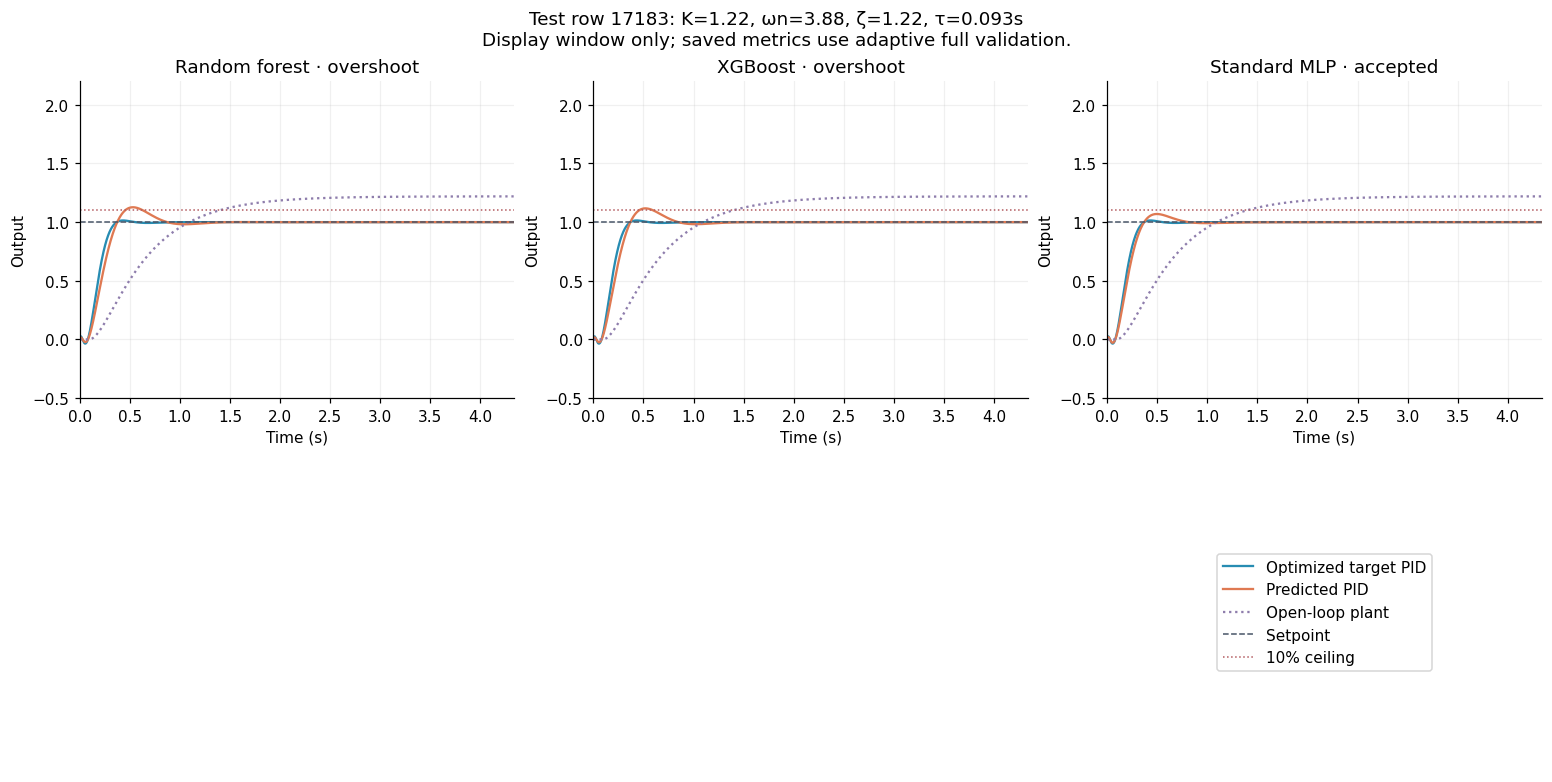

In [24]:
fig = response_plot(large_mlp_predictions, large_mlp_examples["Representative RF overshoot failure"])
plt.show()

In [25]:
print("Some available NEW test row IDs:", large_mlp_protocol["test"][:25])
# To explore a different held-out plant, choose one of the new test IDs:
# new_source_row = large_mlp_protocol["test"][0]
# fig = response_plot(large_mlp_predictions, new_source_row)
# plt.show()

Some available NEW test row IDs: [12552, 4463, 4196, 5712, 13373, 19869, 10439, 13037, 12726, 8665, 14341, 7529, 15697, 5200, 15877, 17931, 17977, 17916, 9204, 6208, 4182, 12310, 15217, 16340, 4967]


### Recheck the illustrated predictions

This repeats the shared simulation checks without fitting models or changing settings. It is nominal ideal-PID/Padé validation, not a hardware or exact-delay guarantee.

In [26]:
large_mlp_checks = revalidate(large_mlp_predictions, large_mlp_protocol,
    source_rows=[large_mlp_examples["Representative RF success"], large_mlp_examples["Representative RF overshoot failure"]])
display(large_mlp_checks)
print("Matching saved outcomes:", large_mlp_checks.matches.sum(), "/", len(large_mlp_checks))

,model,source_row,saved_reason,fresh_reason,matches,overshoot_pct,objective
0,random_forest,7688,accepted,accepted,True,1.030763e-01,0.524945
1,random_forest,17183,overshoot,overshoot,True,1.268045e+01,NaN
2,xgboost,7688,accepted,accepted,True,1.143666e-01,0.523007
3,xgboost,17183,overshoot,overshoot,True,1.173809e+01,NaN
4,standard_mlp,7688,accepted,accepted,True,1.110223e-13,0.532084
5,standard_mlp,17183,accepted,accepted,True,6.926899e+00,0.726273


Matching saved outcomes: 6 / 6


The full new-data report is at `results/dataset_20000/report.md`.
The source CSV and all earlier experiments remain unchanged. To reproduce this new experiment, run `python scripts/train_20000.py`, `python scripts/report_20000.py`, then `python scripts/append_20000_notebooks.py`. Training commands overwrite this experiment's result directory.

# Final study: fresh 10,000-plant dataset

This section is separate from every earlier experiment above. The dataset has **7,000 training / 1,500 validation / 1,500 held-out test plants**. All models use the same five empirical inputs and normalized gain targets. Hyperparameters and model weights were locked before test scoring. These cells load the saved final results; they never retrain or select a model from test outcomes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
FINAL_ROOT = Path.cwd()
if not (FINAL_ROOT / 'src').is_dir():
    FINAL_ROOT = FINAL_ROOT.parent
sys.path.insert(0, str(FINAL_ROOT / 'scripts'))
sys.path.insert(0, str(FINAL_ROOT / 'src'))
from report_final_10000 import load_final, learning_plot as final_learning_plot, history_plot as final_history_plot
from plot_baselines import (style, performance_plot, prediction_plot, failure_plot, objective_plot, itae_plot,
    overshoot_plot, overshoot_bins_plot, example_rows, response_plot)
final_names = ['random_forest', 'xgboost', 'standard_mlp']
FINAL_RESULTS = FINAL_ROOT / 'results' / 'dataset_final_10000'
final_metrics, final_predictions, final_protocol = load_final(final_names)
style()
display(final_metrics[['passes','plants','success_pct','stable_pct','r2','median_ITAE_ratio','median_J_ratio','ratio_pairs']])
display(pd.read_csv(FINAL_RESULTS / 'selected_before_test.csv').query('model in @final_names')[['model','setting','success_pct','median_J_ratio']])
print('Dataset SHA-256:', final_protocol['dataset_sha256'])

,passes,plants,success_pct,stable_pct,r2,median_ITAE_ratio,median_J_ratio,ratio_pairs
model,,,,,,,,
random_forest,1301,1500,86.733333,100.0,0.940967,1.067729,1.065512,1301
xgboost,1272,1500,84.800000,100.0,0.957534,1.136830,1.122313,1272
standard_mlp,1406,1500,93.733333,100.0,0.979401,1.057748,1.057760,1406


,model,setting,success_pct,median_J_ratio
3,random_forest,depthNone_leaf1,86.933333,1.056718
4,xgboost,trees400,85.333333,1.114237
5,standard_mlp,standard,95.333333,1.061717


Dataset SHA-256: e86f0039c0747afa186a322bdc89f77b99f03a1ba9aaa77a40c6243e64d97089


## Regression accuracy and controller acceptance

Gain errors use all 1,500 test plants, including failed controllers. Acceptance requires finite bounded gains, stable poles, refined overshoot ≤10%, a settled tail and resolved numerical checks. Predictions are evaluated without clipping or a fallback.

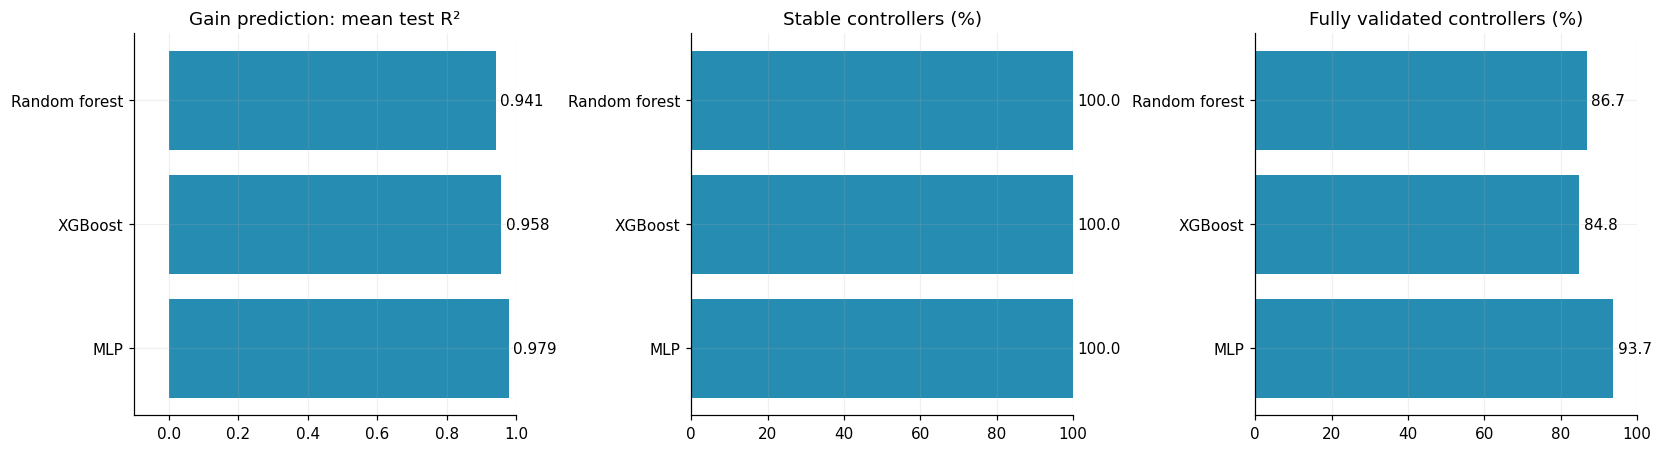

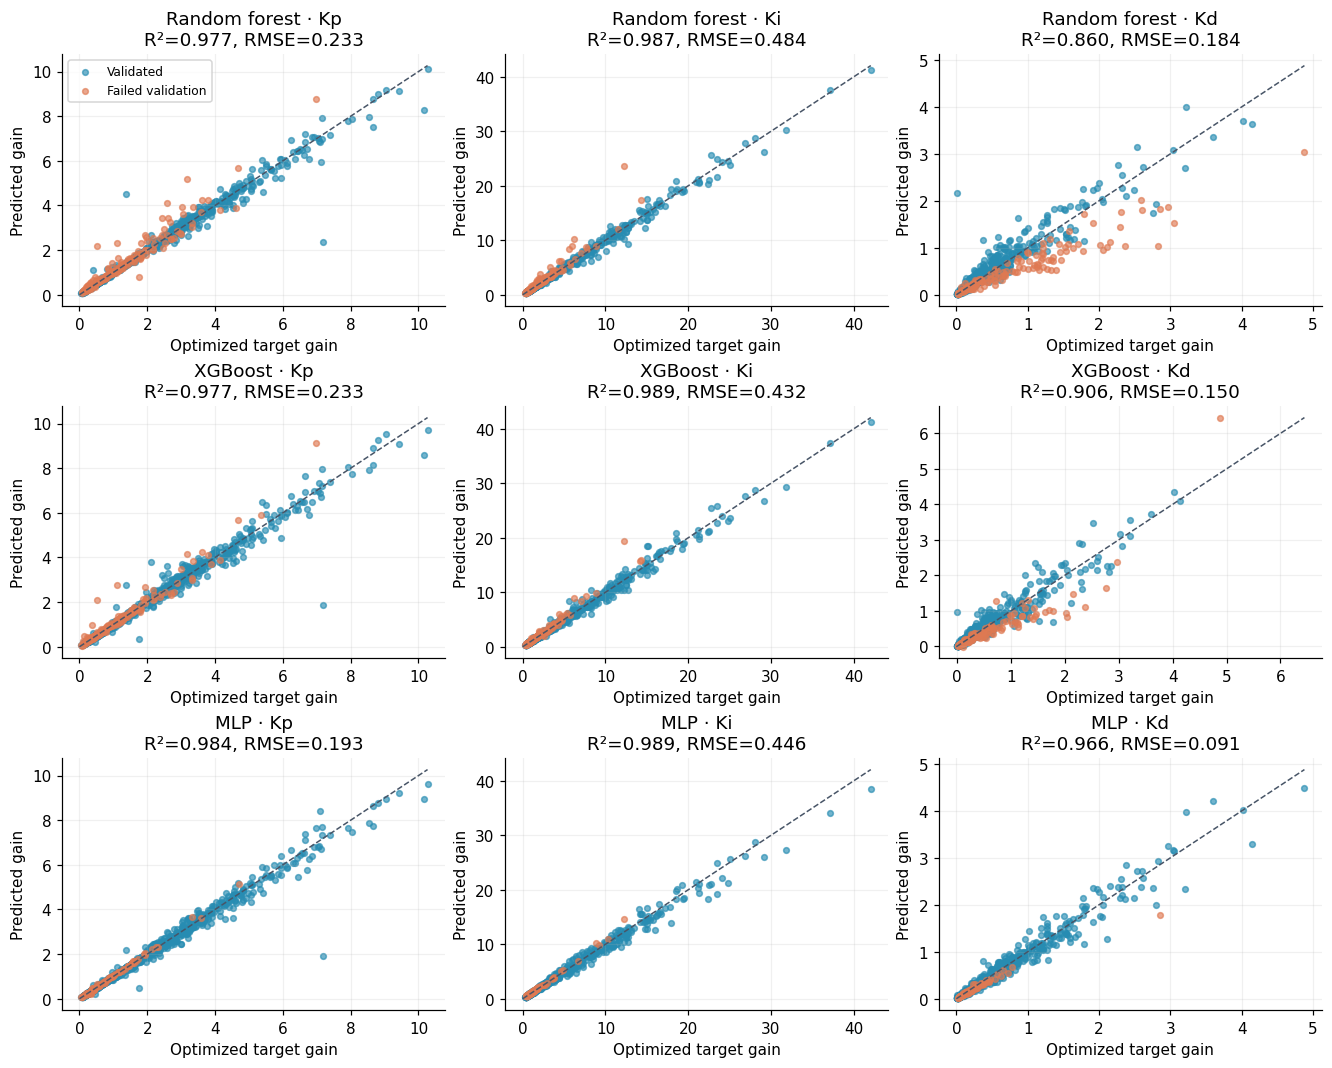

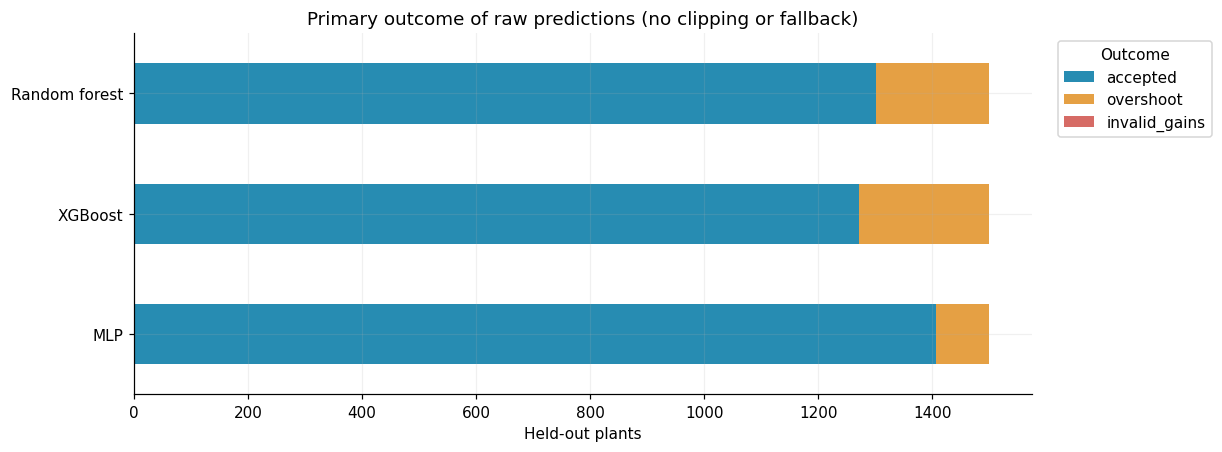

,model,gain,MAE,RMSE,R2
9,random_forest,Kp,0.077666,0.232713,0.976857
10,random_forest,Ki,0.155230,0.483878,0.986532
11,random_forest,Kd,0.066879,0.183790,0.859512
12,xgboost,Kp,0.084053,0.232643,0.976870
13,xgboost,Ki,0.171738,0.431751,0.989278
14,xgboost,Kd,0.059244,0.149974,0.906454
15,standard_mlp,Kp,0.062899,0.193354,0.984023
16,standard_mlp,Ki,0.165383,0.446052,0.988556
17,standard_mlp,Kd,0.033747,0.090914,0.965624


In [2]:
# Gain agreement does not by itself certify a usable controller.
for final_plotter in [performance_plot, prediction_plot, failure_plot]:
    final_figure = final_plotter(final_metrics if final_plotter is performance_plot else final_predictions)
    plt.show()
    plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'gain_errors.csv').query('model in @final_names'))

## ITAE and regularized cost relative to numerical tuning

**ITAE ratio = predicted ITAE / reference ITAE.** One means equal tracking cost. Percentage change is 100 × (ratio − 1). Ratios use only pairs where both controllers pass; coverage is shown and differs across models. Inspect upper tails as well as medians. The teacher minimizes J = ωₙ² ITAE + 0.01 times a dimensionless squared-gain penalty, so lower raw ITAE need not imply lower J.

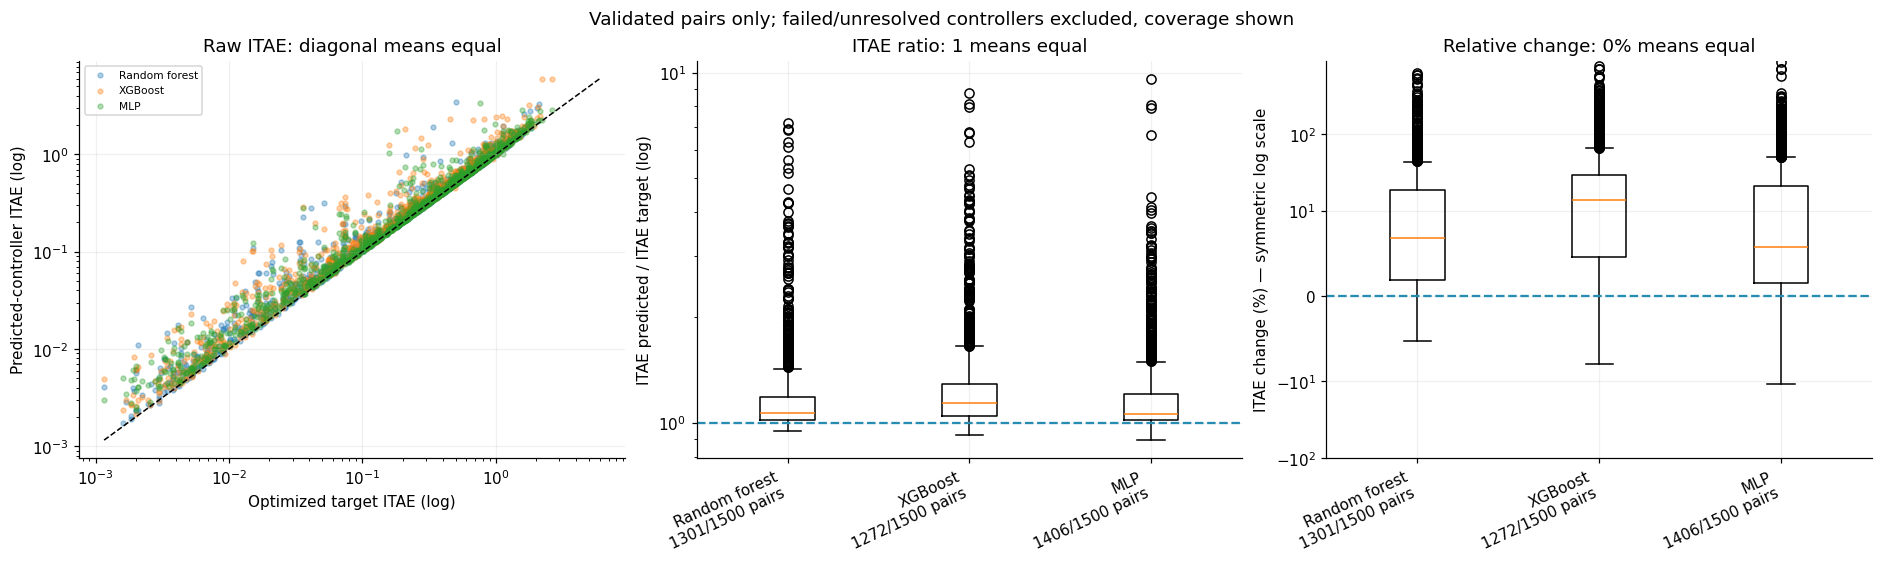

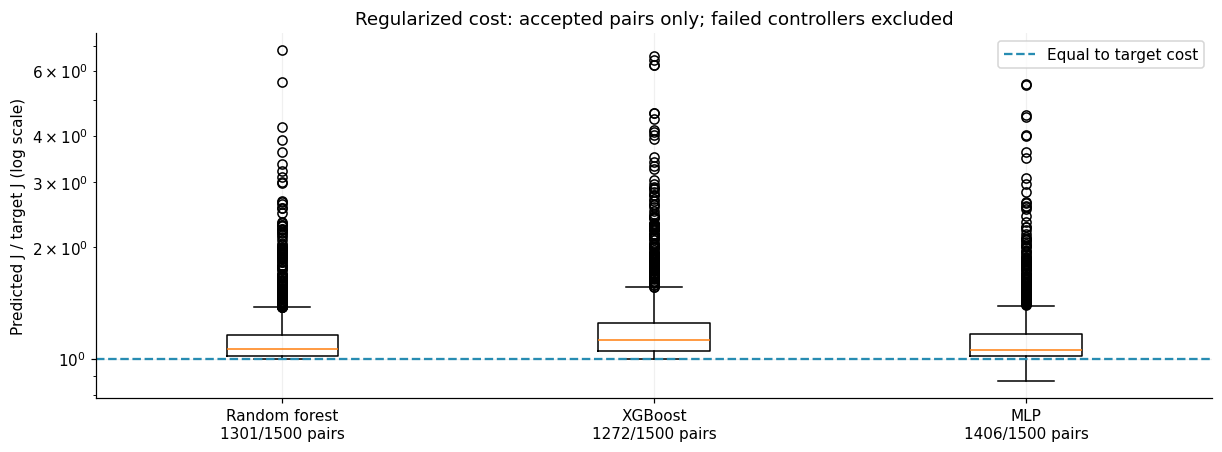

,model,pairs,median_ITAE_ratio,median_change_pct,p90_ITAE_ratio,p95_ITAE_ratio,max_ITAE_ratio,ITAE_over_2x
3,random_forest,1301,1.067729,6.772936,1.537953,1.971886,7.155548,63
4,xgboost,1272,1.136830,13.682982,1.801617,2.518548,8.745563,98
5,standard_mlp,1406,1.057748,5.774802,1.599990,2.103508,9.612143,78


In [3]:
for final_plotter in [itae_plot, objective_plot]:
    final_figure = final_plotter(final_predictions)
    plt.show()
    plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'itae_summary.csv').query('model in @final_names'))

## Overshoot severity and error groups

The threshold curve uses **all 1,500 test plants** as its denominator. Unstable and unmeasured responses are separate, not assigned zero overshoot. Overshoot below 10% alone is not full acceptance. Physical delay/damping groups are descriptive audits, not prediction inputs or grounds for retuning.

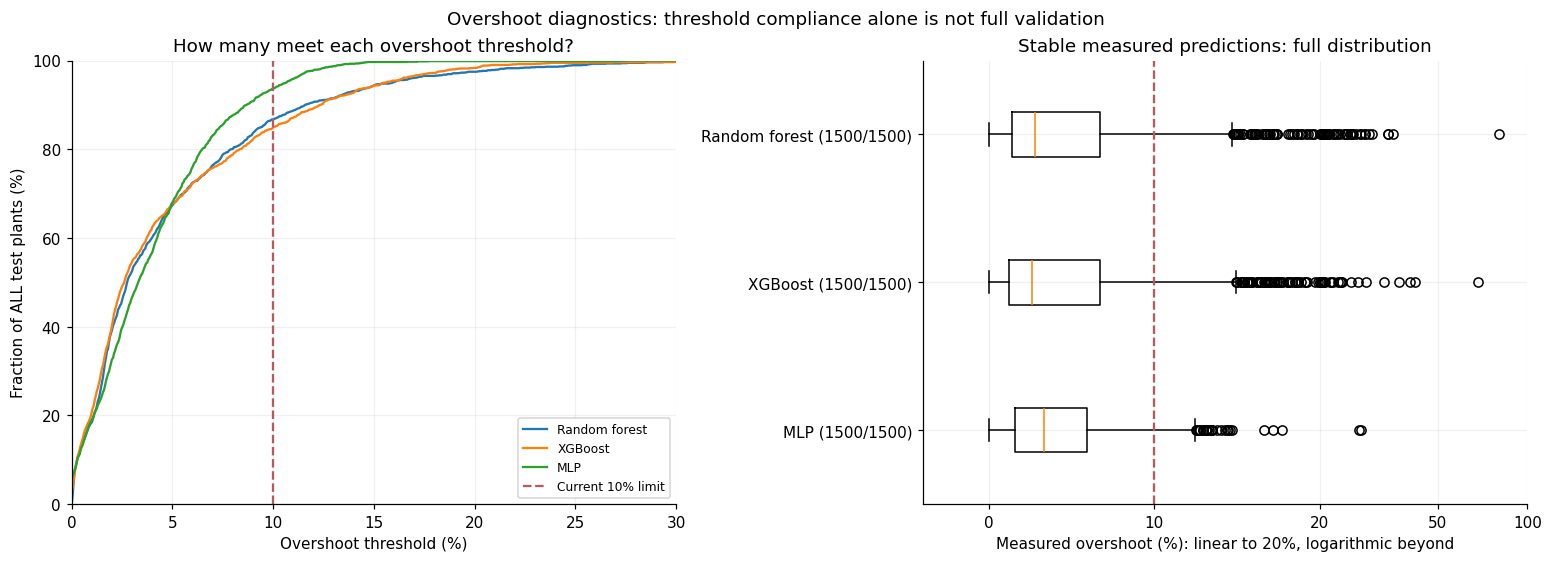

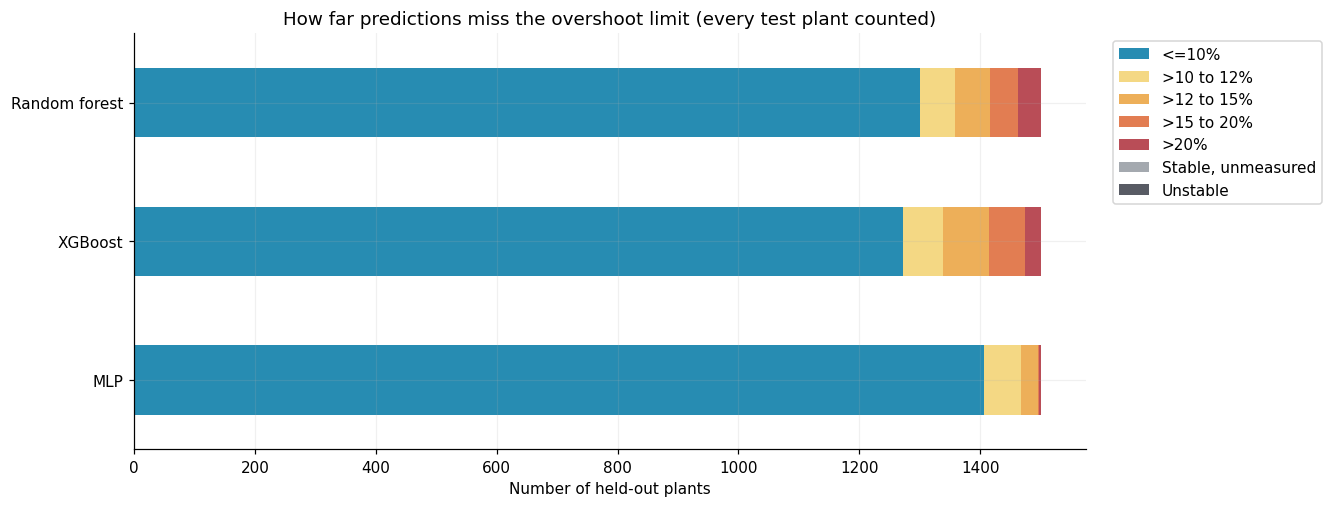

,model,test_plants,measured_stable,at_most_10,over_10_to_12,over_12_to_15,over_15_to_20,over_20,stable_unmeasured,unstable,median_overshoot_pct,p90_overshoot_pct,max_overshoot_pct,median_excess_pp,p90_excess_pp,full_validation_passes
3,random_forest,1500,1500,1301,58,57,46,38,0,0,2.756464,11.564511,80.031357,4.339645,14.211811,1301
4,xgboost,1500,1500,1273,65,76,61,25,0,0,2.608828,12.289599,68.463764,3.751705,10.164936,1272
5,standard_mlp,1500,1500,1406,61,28,3,2,0,0,3.300628,8.658827,27.527092,1.426315,4.205017,1406


,model,reason,plants
17,random_forest,accepted,1301
18,random_forest,overshoot,199
19,xgboost,accepted,1272
20,xgboost,overshoot,227
21,xgboost,invalid_gains,1
22,standard_mlp,accepted,1406
23,standard_mlp,overshoot,94


,model,group,plants,passes,success_pct
21,random_forest,zero delay,154,141,91.558442
22,random_forest,0 < delay <= 0.1,122,103,84.426230
23,random_forest,0.1 < delay <= 0.5,552,458,82.971014
24,random_forest,delay > 0.5,672,599,89.136905
25,random_forest,zeta < 0.5,317,252,79.495268
26,random_forest,0.5 <= zeta < 1,373,278,74.530831
27,random_forest,zeta >= 1,810,771,95.185185
28,xgboost,zero delay,154,149,96.753247
29,xgboost,0 < delay <= 0.1,122,113,92.622951
30,xgboost,0.1 < delay <= 0.5,552,442,80.072464


In [4]:
for final_plotter in [overshoot_plot, overshoot_bins_plot]:
    final_figure = final_plotter(final_predictions)
    plt.show()
    plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'overshoot_summary.csv').query('model in @final_names'))
display(pd.read_csv(FINAL_RESULTS / 'failure_counts.csv').query('model in @final_names'))
display(pd.read_csv(FINAL_RESULTS / 'group_results.csv').query('model in @final_names'))

## Learning curves: validation data only

The same nested 1,000 / 3,000 / 5,000 / 7,000 training subsets are used across models, with fixed selected settings. Every point uses the same 500 stratified validation plants. MLP stopping uses the full validation partition. These are development diagnostics, not independent holdout estimates; the final test set is never used for the curves.

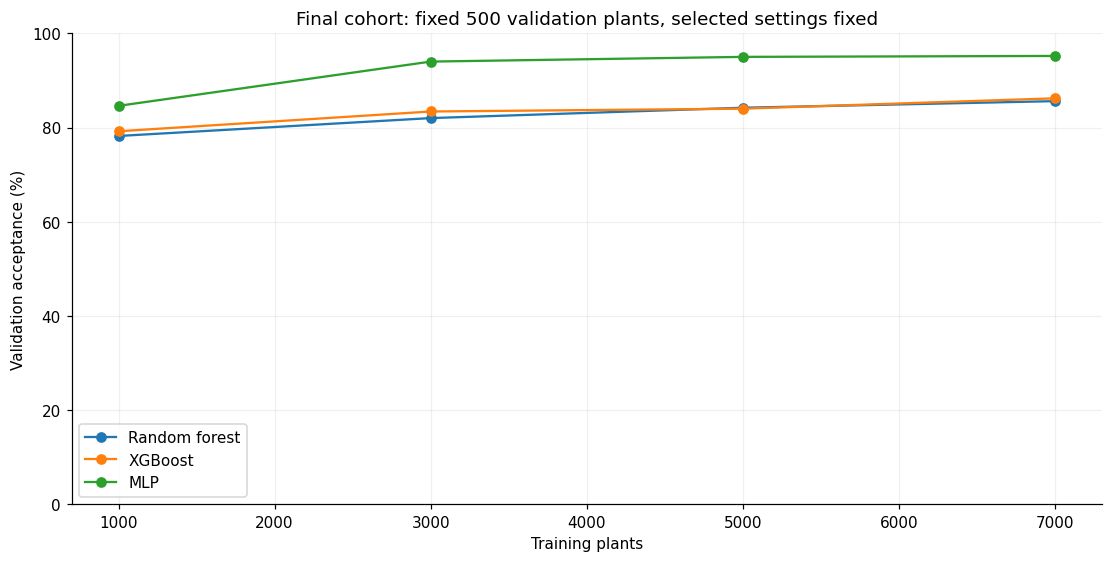

,model,training_size,success_pct,r2,median_J_ratio
15,random_forest,1000,78.2,0.869675,1.095424
16,random_forest,3000,82.0,0.910941,1.076217
17,random_forest,5000,84.2,0.904079,1.062374
3,random_forest,7000,85.6,0.917130,1.055232
21,standard_mlp,1000,84.6,0.935920,1.121304
22,standard_mlp,3000,94.0,0.968431,1.079840
23,standard_mlp,5000,95.0,0.974593,1.060278
5,standard_mlp,7000,95.2,0.983559,1.054856
18,xgboost,1000,79.2,0.906827,1.167233
19,xgboost,3000,83.4,0.948264,1.135879


In [5]:
final_figure = final_learning_plot(final_names)
plt.show()
plt.close(final_figure)
display(pd.read_csv(FINAL_RESULTS / 'learning_curves.csv').query('model in @final_names').sort_values(['model','training_size'])[['model','training_size','success_pct','r2','median_J_ratio']])

## MLP training and early stopping

Three hidden layers (128, 64, 32), SiLU, dropout 0.05, positive normalized outputs and standardized log loss. Training restores the best validation-loss epoch; these curves do not alter the frozen model.

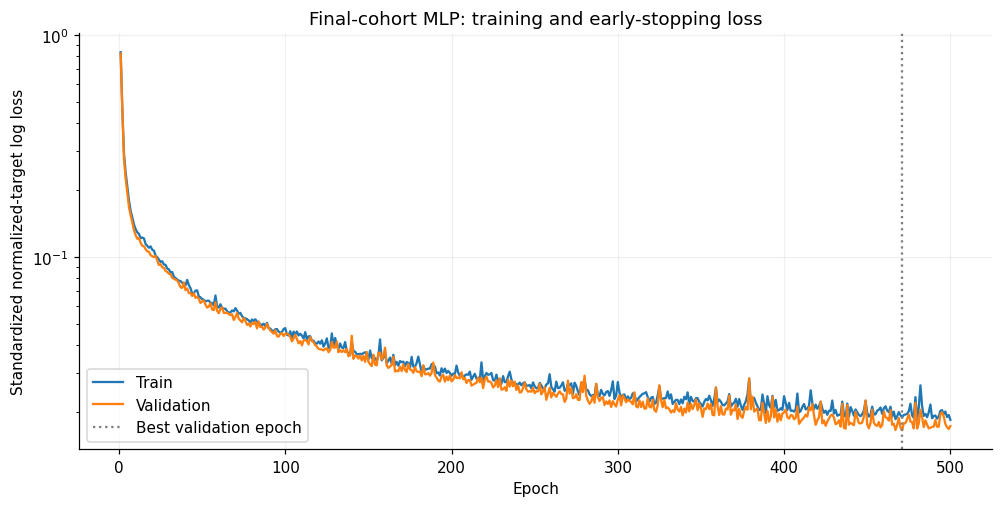

In [6]:
final_figure = final_history_plot()
plt.show()
plt.close(final_figure)

## Shared response examples

These examples are selected transparently from random-forest outcomes (median accepted J ratio and median stable overshoot miss). They illustrate behavior rather than estimate overall accuracy. Plotting stored gains does not rerun model selection or full test validation.

Representative RF success              8150
Representative RF overshoot failure    5607
Zero-delay example                       38
Name: Final-cohort CSV row, dtype: int64

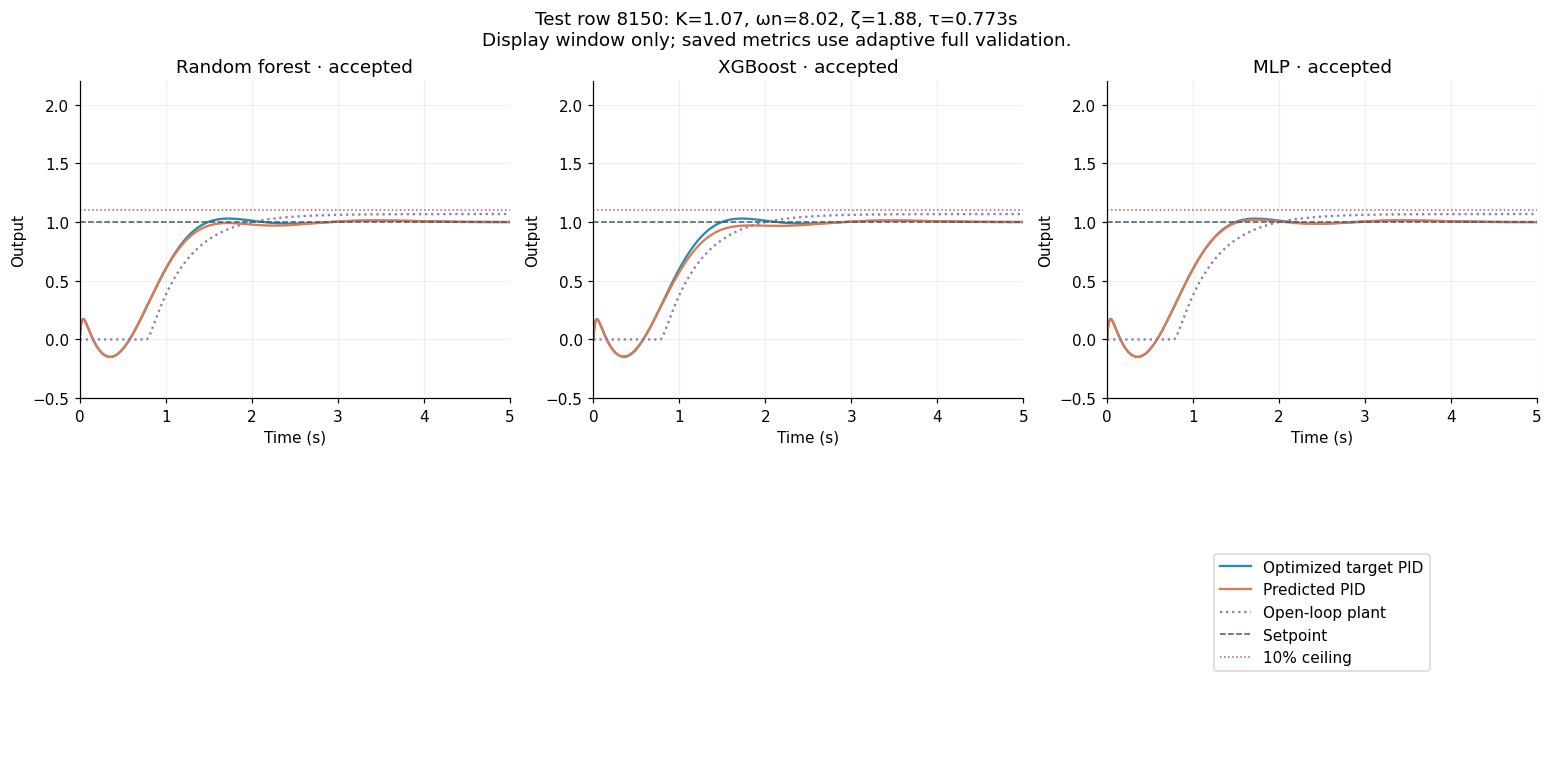

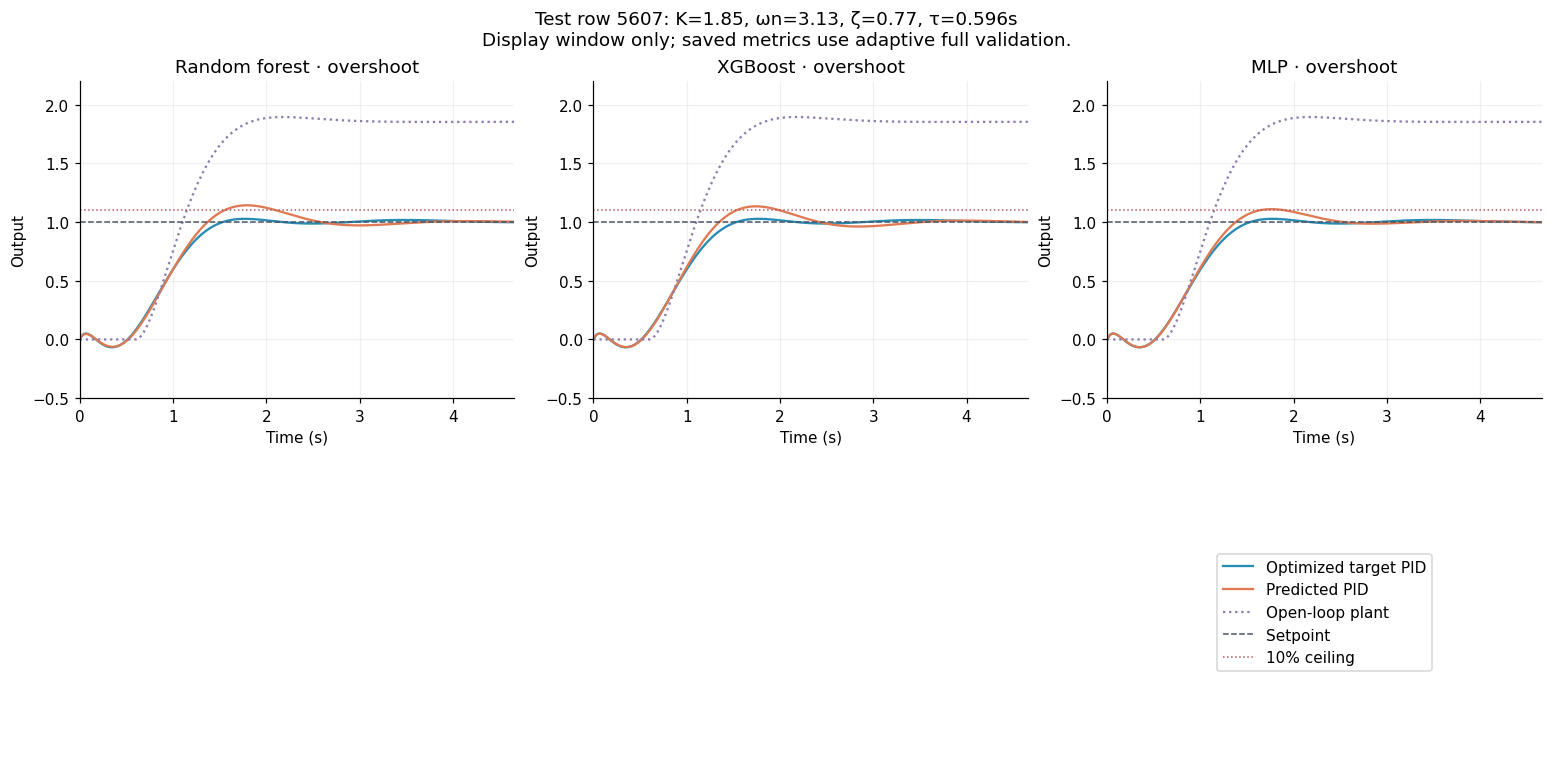

In [7]:
final_examples = example_rows(final_predictions)
display(pd.Series(final_examples, name='Final-cohort CSV row'))
for final_case in ['Representative RF success','Representative RF overshoot failure']:
    final_figure = response_plot(final_predictions, final_examples[final_case])
    plt.show()
    plt.close(final_figure)

## Verification and limits

The numerical target controllers were revalidated, all saved models reproduce their scored gains, and locked model/settings/data hashes remain unchanged. The held-out scores concern one split and seed within the accepted-label SOPDT population. Ideal PID and second-order Padé delay are approximations; there is no exact-delay, actuator/noise or hardware safety guarantee. Earlier 20K results use a different test cohort and are not a controlled sample-size comparison.

Full report: `results/dataset_final_10000/report.md`. Reproduce training with `python scripts/train_final_10000.py` in a separate unscored workspace; the runner deliberately refuses to overwrite this locked experiment.

In [8]:
display(pd.read_csv(FINAL_RESULTS / 'acceptance_intervals.csv').query('model in @final_names'))
display(json.loads((FINAL_RESULTS / 'verification.json').read_text(encoding='utf-8')))

,model,acceptance_pct,Wilson95_low,Wilson95_high
3,random_forest,86.733333,84.922500,88.356501
4,xgboost,84.800000,82.894389,86.527823
5,standard_mlp,93.733333,92.391603,94.851636


{'split_sizes': {'train': 7000, 'validation': 1500, 'test': 1500},
 'dataset_hash_unchanged': True,
 'all_locked_artifact_hashes_unchanged': True,
 'saved_prediction_max_abs_difference': {'linear': 0.0,
  'ridge': 0.0,
  'polynomial_ridge': 0.0,
  'random_forest': 2.1316282072803006e-14,
  'xgboost': 0.0,
  'standard_mlp': 0.0},
 'validation_reference_accepted': 1500,
 'test_reference_accepted': 1500,
 'test_scored_once_per_model': True,
 'seconds': 1078.5060755000013}